# Impact of Dried Blood Spot Diameter and Transit Time on Analyte Concentrations and Cut-Off Classification in Routine Newborn Screening

## Repeat samples - data analysis

This Jupyter notebook describes the analysis of initial newborn screening results to assess the impact of transit time on results, part of the following manuscript:

Flynn N, Hogg S, Moat SJ. Impact of dried blood spot diameter and transit time on analyte concentrations and cut-off classification in routine newborn screening. *Clinical Chemistry and Laboratory Medicine*. 2026.

**DOI:** https://doi.org/10.1515/cclm-2026-0976

Please cite this paper if you re-use any of the code in this analysis.

### Library imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import math
import seaborn as sns
from datetime import datetime, timedelta
import string
from scipy import stats
import statsmodels.api as sm

In [2]:
sns.set_style("whitegrid")

# Import data

### Results

Import results for samples received between April 2015 and October 2025

In [3]:
tsh = pd.read_csv('data/chtpopulationsd_0415-1025.csv', parse_dates=["Date Rec'd", "Sample Date"], dayfirst=True, low_memory=False)
irt = pd.read_csv('data/cfpopulationsd_0415-1025.csv', parse_dates=["Date Rec'd", "Sample Date"], dayfirst=True, low_memory=False)
imd = pd.read_csv('data/imdpopulationsd_0415-1025.csv', parse_dates=["Date Rec'd", "Sample Date"], dayfirst=True, low_memory=False)

Preview data:

In [4]:
tsh.head()

,Date Rec'd,Sample Date,TSH,Age,Episode_pseudo
0,2015-04-01,2015-03-31,1.0,5.0,EPI1504689
1,2015-04-01,2015-03-31,1.0,5.0,EPI1504690
2,2015-04-01,2015-03-29,3.0,5.0,EPI1504691
3,2015-04-01,2015-03-28,1.0,5.0,EPI1504692
4,2015-04-01,2015-03-30,1.0,5.0,EPI1504693


In [5]:
def report_counts(tshdf, irtdf, imddf):
    print("TSH: " + str(len(tshdf)))
    print("IRT: " + str(len(irtdf)))
    print("IMD: " + str(len(imddf)))

In [6]:
report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 277012
IRT: 265295
IMD: 274039


Dataframes include greater than and less than values. Replace with numeric placehold values then convert column to numeric

In [7]:
def handle_lt_gt(df,analyte):
    # Ensure string dtype
    df[analyte] = df[analyte].astype(str)
    
    # Handle < values
    mask_lt = df[analyte].str.startswith("<", na=False)
    df.loc[mask_lt, analyte] = (
    df.loc[mask_lt, analyte]
       .str.replace("<", "", regex=False)
       .astype(float) * 1
    )

    # Handle > values
    mask_gt = df[analyte].str.startswith(">", na=False)
    df.loc[mask_gt, analyte] = (
    df.loc[mask_gt, analyte]
       .str.replace(">", "", regex=False)
       .astype(float) * 1
    )
    
    df[analyte] = pd.to_numeric(df[analyte], errors="coerce")

In [8]:
imd_cols = ['C10', 'C8', 'Phe', 'Tyr', 'C5', 'C5DC', 'Met', 'Xleu']

In [9]:
handle_lt_gt(tsh,"TSH")
handle_lt_gt(irt,"IRT")

for col in imd_cols:
    handle_lt_gt(imd,col)
    
report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 277012
IRT: 265295
IMD: 274039


Add column for year month and year (needed later for experiments on seasonal variability)

In [10]:
tsh['month_no'] = tsh["Date Rec'd"].dt.year
irt['month_no'] = irt["Date Rec'd"].dt.year
imd['month_no'] = imd["Date Rec'd"].dt.year

tsh['year'] = tsh["Date Rec'd"].dt.year
irt['year'] = irt["Date Rec'd"].dt.year
imd['year'] = imd["Date Rec'd"].dt.year

tsh['year_month'] = tsh["Date Rec'd"].dt.to_period('M')
irt['year_month'] = irt["Date Rec'd"].dt.to_period('M')
imd['year_month'] = imd["Date Rec'd"].dt.to_period('M')

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 277012
IRT: 265295
IMD: 274039


### DBS metrics

Load DBS metrics, obtained using methods described in the following paper.

    Flynn N, Moat SJ, Hogg SL. A computer vision approach to the assessment of dried blood spot size and quality in newborn screening. Clin Chim Acta. 2023;547:117418.

Data is stored by Panthera instrument and month, so we load each each month separately before combining into a single dataframe. 

Note this is for all images obtained from the Panthera. We will merge with just the samples we need later.

In [11]:
## Old Panthera
year = (2015,2016,2017,2018,2019,2020,2021,2022,2023)
month = (1,2,3,4,5,6,7,8,9,10,11,12)
dataframes = []

for y in year:
    for m in month:
        try:
            filepath = 'data/dbs_metrics/' + str(y) + '-' + str(m) + '.csv'
            df_month = pd.read_csv(filepath,parse_dates=['month','date_time'])
            dataframes.append(df_month)
        except:
            print('No data for year ' + str(y) + ' and month ' + str(m))
            
## New Panthera
year = (2023,2024,2025)
month = (1,2,3,4,5,6,7,8,9,10,11,12)

for y in year:
    for m in month:
        try:
            filepath = 'data/dbs_metrics/' + str(y) + '-' + str(m) + '_new.csv'
            df_month = pd.read_csv(filepath,parse_dates=['month','date_time'])
            dataframes.append(df_month)
        except:
            print('No data for year ' + str(y) + ' and month ' + str(m))

No data for year 2015 and month 1
No data for year 2023 and month 11
No data for year 2023 and month 12
No data for year 2023 and month 1
No data for year 2023 and month 2
No data for year 2023 and month 3
No data for year 2023 and month 4
No data for year 2023 and month 5
No data for year 2023 and month 6
No data for year 2023 and month 7
No data for year 2023 and month 8
No data for year 2023 and month 9
No data for year 2025 and month 11
No data for year 2025 and month 12


In [12]:
dbs_metrics = pd.concat(dataframes,ignore_index=True)

In [13]:
len(dbs_metrics)

423390

Add columns for total and running total of punches, and the starting number of punches - these will be used to work out which image corresponds to which punch (assuming IMD first, TSH second and IRT third)

First convert number of punches to numeric datatype

In [14]:
dbs_metrics['number_punches'] = pd.to_numeric(
    dbs_metrics['number_punches'], errors='coerce'
)

In [15]:
g = dbs_metrics.groupby('Episode_pseudo')

totals = g['number_punches'].transform('sum')
running = g['number_punches'].cumsum()

dbs_metrics['total_punches'] = totals
dbs_metrics['running_punches'] = running
dbs_metrics['start_punch'] = running - dbs_metrics['number_punches']

IMD is punched first, so is include if we have start without any punches

In [16]:
dbs_metrics['IMDp'] = False
dbs_metrics.loc[(dbs_metrics['start_punch'] == 0)
    & (dbs_metrics['number_punches'] >= 1),'IMDp'] = True

TSH is punched second, so is included if we have more than 2 punches, start without any punches and punch more than one punch, or begin after punching 1 spot and punch any number of punches.

Note this won't include repeat samples collected due to a previous borderline result or  prem repeat

In [17]:
dbs_metrics['TSHp'] = False
dbs_metrics.loc[(dbs_metrics['start_punch'] == 0)
    & (dbs_metrics['number_punches'] >= 2),'TSHp'] = True

dbs_metrics.loc[(dbs_metrics['start_punch'] == 1)
    & (dbs_metrics['number_punches'] >= 1),'TSHp'] = True

IRT is punched third, so is included if we have more than 3 punches in total, we start without any punches and punch 3 or more punches, after 1 punch and punch 2 or more, or after 2 punches and punch 1

In [18]:
dbs_metrics['IRTp'] = False
dbs_metrics.loc[(dbs_metrics['start_punch'] == 0)
    & (dbs_metrics['number_punches'] >= 3),'IRTp'] = True
                 
dbs_metrics.loc[(dbs_metrics['start_punch'] == 1)
    & (dbs_metrics['number_punches'] >= 2),'IRTp'] = True
                 
dbs_metrics.loc[(dbs_metrics['start_punch'] == 2)
    & (dbs_metrics['number_punches'] >= 1),'IRTp'] = True

Exclude incorrect blood application samples

In [19]:
dbs_metrics = dbs_metrics[dbs_metrics['pred_multi'] == 'controls']

In [20]:
len(dbs_metrics)

392881

Separate DBS metrics for three tests

In [21]:
imd_dbsmetrics = dbs_metrics[dbs_metrics['IMDp'] == True]
tsh_dbsmetrics = dbs_metrics[dbs_metrics['TSHp'] == True]
irt_dbsmetrics = dbs_metrics[dbs_metrics['IRTp'] == True]

In [22]:
report_counts(tshdf=tsh_dbsmetrics,irtdf=irt_dbsmetrics,imddf=imd_dbsmetrics)

TSH: 261558
IRT: 257616
IMD: 265785


Merge with results

In [23]:
tsh = tsh.merge(tsh_dbsmetrics,left_on='Episode_pseudo',right_on='Episode_pseudo')
irt = irt.merge(irt_dbsmetrics,left_on='Episode_pseudo',right_on='Episode_pseudo')
imd = imd.merge(imd_dbsmetrics,left_on='Episode_pseudo',right_on='Episode_pseudo')

In [24]:
report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 257429
IRT: 246449
IMD: 257519


## Data processing

Add column for transit time (days to receive sample)

In [25]:
tsh["Days to receive"] = ((tsh["Date Rec'd"] - tsh["Sample Date"]).dt.days).astype("Int64") 
irt["Days to receive"] = ((irt["Date Rec'd"] - irt["Sample Date"]).dt.days).astype("Int64") 
imd["Days to receive"] = ((imd["Date Rec'd"] - imd["Sample Date"]).dt.days).astype("Int64") 

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 257429
IRT: 246449
IMD: 257519


Drop any blank values where there is no result:

In [26]:
tsh = tsh[~tsh["TSH"].isna()]
irt = irt[~irt["IRT"].isna()]

for col in imd_cols:
    imd = imd[~imd[col].isna()]

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 257426
IRT: 246448
IMD: 257508


Drop any TSH before May 2018 (integer values only)

In [27]:
tsh = tsh[tsh["Date Rec'd"] > "2018-05-07"]

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 181277
IRT: 246448
IMD: 257508


Drop anything with missing sample date

In [28]:
tsh = tsh[~tsh["Sample Date"].isna()]
irt = irt[~irt["Sample Date"].isna()]
imd = imd[~imd["Sample Date"].isna()]

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 180699
IRT: 246448
IMD: 256543


Drop results above analytical cut-off value

In [29]:
#create copy of dataframes without exclusions
# (we will use these to plot summary population statistics so don't want to exclude results above CoVs)
tsh_noexc = tsh.copy()
irt_noexc = irt.copy()
imd_noexc = imd.copy()

## exclude if above analytical cut-offs
tsh = tsh[tsh['TSH'] < 6.0]
irt = irt[irt['IRT'] < 46.0]
imd = imd[imd['C10'] < 0.4]
imd = imd[imd['C8'] < 0.4]
imd = imd[imd['Phe'] < 200]
imd = imd[imd['Tyr'] < 200]
imd = imd[imd['C5'] < 1.6]
imd = imd[imd['C5DC'] < 0.56]
imd = imd[imd['Met'] < 45]
imd = imd[imd['Xleu'] < 500]

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 179597
IRT: 243086
IMD: 245803


In [30]:
imd['equiv_diam_mm'].describe()

count    245803.000000
mean         10.631946
std           1.036007
min           2.799464
25%           9.995874
50%          10.653290
75%          11.282562
max          18.671354
Name: equiv_diam_mm, dtype: float64

For each result, calculate difference from daily mean (only if more than 10 samples in reference population per day)

In [31]:
def compute_daily_mean(df, value_col, min_rows=10):
    """
    Compute the daily mean of `value_col` for rows with
    Days to receive == 1 and equiv_diam_mm in (10, 12],
    and set mean to NaN if fewer than `min_rows`.
    """
    # Mask for rows to include in the mean
    mask = (df["Days to receive"] == 1) & (df['equiv_diam_mm'] > 10) & (df['equiv_diam_mm'] <= 12)

    # Count rows per date
    count_per_date = mask.groupby(df["Date Rec'd"]).transform("sum")

    # Compute mean per date
    mean_per_date = df[value_col].where(mask).groupby(df["Date Rec'd"]).transform("mean")

    # Set mean to NaN if fewer than min_rows
    mean_per_date[count_per_date < min_rows] = np.nan

    df[f"Mean_{value_col}_by_Date_Rec'd"] = mean_per_date
    return df

In [32]:
compute_daily_mean(tsh, "TSH")
compute_daily_mean(irt, "IRT")

for col in imd_cols:
    compute_daily_mean(imd, col)

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 179597
IRT: 243086
IMD: 245803


Some of the daily means are very low and show variability. Lets inspect these a bit closer.

In [33]:
def compute_daily_cv(df, value_col):

    mask = (
        (df["Days to receive"] == 1) &
        (df["equiv_diam_mm"] > 10) &
        (df["equiv_diam_mm"] <= 12)
    )

    daily = (
        df.loc[mask]
          .groupby("Date Rec'd")[value_col]
          .agg(["mean", "std", "count"])
          .rename(columns={"mean": "mean", "std": "sd"})
    )

    daily["cv"] = daily["sd"] / daily["mean"]

    return daily

In [34]:
def plot_daily_mean_CV(df, analyte):
    plt.figure(figsize=(8,6),dpi=100)
    plt.title(analyte)
    daily_stats = compute_daily_cv(df, analyte)
    plt.scatter(daily_stats["mean"], daily_stats["cv"], alpha=0.3)
    plt.xlabel("Daily mean")
    plt.ylabel("CV")

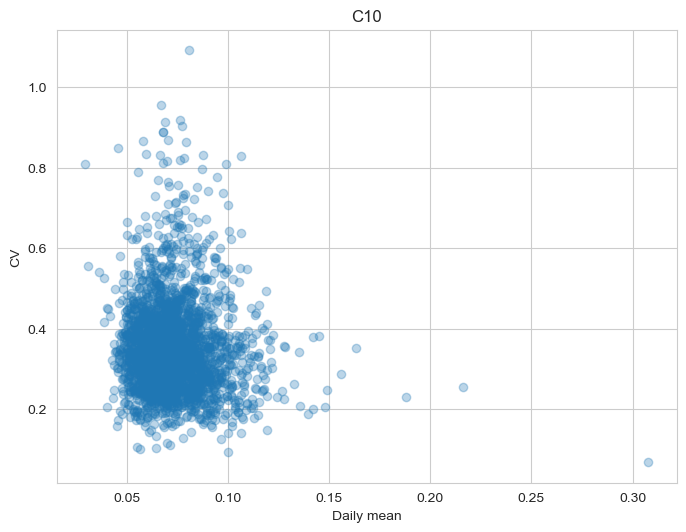

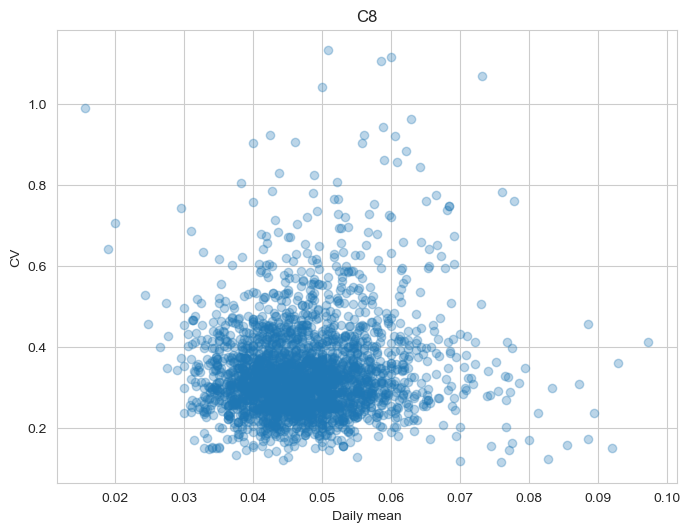

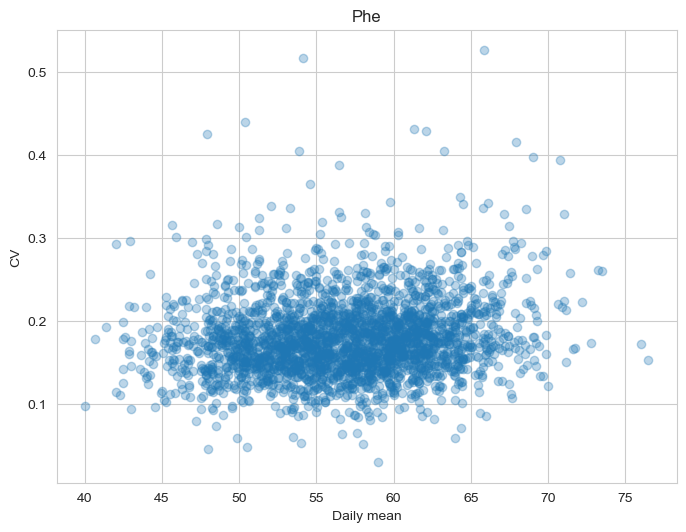

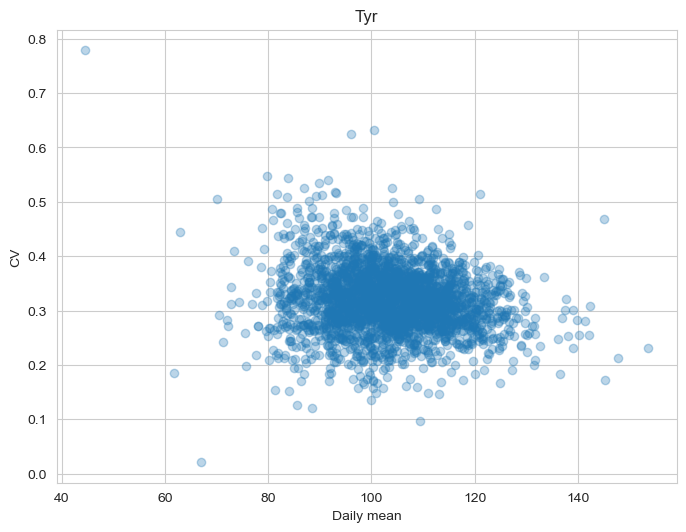

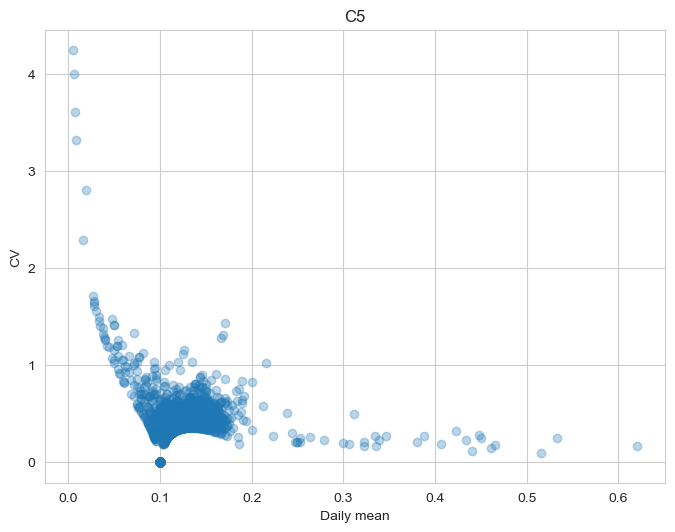

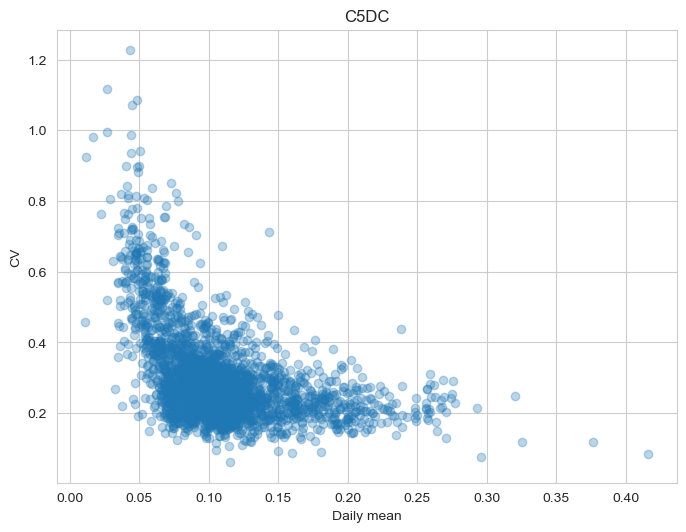

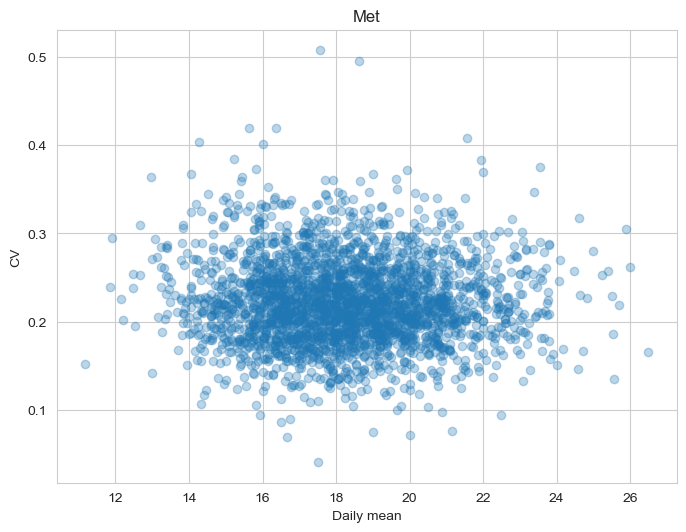

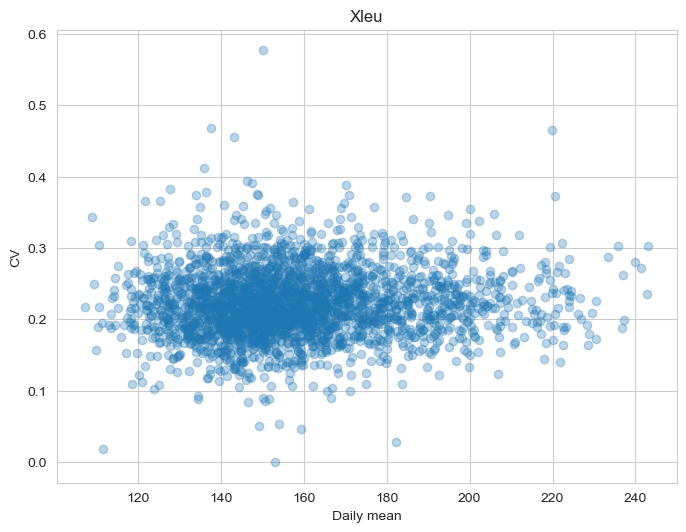

In [35]:
for col in imd_cols:
    plot_daily_mean_CV(imd,col)

Drop any daily means with low C5 or C5DC daily means as they are dominated by noise

In [36]:
imd = imd[imd["Mean_C5_by_Date_Rec'd"] >= 0.05]
imd = imd[imd["Mean_C5DC_by_Date_Rec'd"] >= 0.02]

Now calculate the difference and percent difference from the daily mean

In [37]:
def compute_diff_from_mean(df, value_col):
    """
    Compute difference and percent difference from daily mean.
    """
    mean_col = f"Mean_{value_col}_by_Date_Rec'd"
    diff_col = f"{value_col.lower()}_diff_from_daily_mean"
    pct_col = f"{value_col.lower()}_%_diff_from_daily_mean"

    df[diff_col] = df[value_col] - df[mean_col]
    df[pct_col] = df[diff_col] / df[mean_col] * 100
    return df


In [38]:
compute_diff_from_mean(tsh, "TSH")
compute_diff_from_mean(irt, "IRT")

for col in imd_cols:
    compute_diff_from_mean(imd, col)

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 179597
IRT: 243086
IMD: 227032


Drop any results where the % difference from daily mean has not been calculated (for example, if the daily mean is not calculated because there are insufficient samples)

In [39]:
tsh = tsh[~tsh["tsh_%_diff_from_daily_mean"].isna()]
irt = irt[~irt["irt_%_diff_from_daily_mean"].isna()]

for col in imd_cols:
    imd[~imd[f"{col.lower()}_%_diff_from_daily_mean"].isna()]

report_counts(tshdf=tsh,irtdf=irt,imddf=imd)

TSH: 175774
IRT: 225602
IMD: 227032


Calculate the percentage of samples not received within 7 calendar days (used in the discussion)

In [40]:
# Combine all dataframes into one long dataframe with an 'Analyte' column
dfs = {'TSH': tsh, 'IRT': irt, 'IMD': imd}
long_df = pd.concat(
    [df.assign(Analyte=name) for name, df in dfs.items()],
    ignore_index=True
)

# Calculate proportion >= 7 and pivot to wide format
props_wide = (
    long_df.assign(days_gt_7 = long_df['Days to receive'] >= 7)  # boolean
    .groupby(['year', 'Analyte'])['days_gt_7'].mean()          # proportion
    .reset_index()
    .pivot(index='year', columns='Analyte', values='days_gt_7')
)

props_wide=props_wide*100
props_wide

Analyte,IMD,IRT,TSH
year,,,
2015,1.203359,1.175626,NaN
2016,1.408744,1.347186,NaN
2017,1.157018,1.055780,NaN
2018,1.732017,1.679945,1.633051
2019,0.844136,0.829894,0.835244
2020,0.903960,0.759885,0.844458
2021,0.682814,0.673032,0.676943
2022,0.608556,0.603532,0.622398
2023,0.499347,0.524596,0.545525


## Ordinary least squares analysis

Define a function to perform ordinary least squares analysis for each dataframe

In [41]:
def ols_multivariate(df, predictors=['Days to receive', 'equiv_diam_mm']):
    results = []
    
    # Detect analyte columns
    analyte_cols = [col for col in df.columns if col.endswith("%_diff_from_daily_mean")]
    
    for col in analyte_cols:
        # Prepare outcome and predictors
        y = df[col]
        X = df[predictors].astype(float)
        X = sm.add_constant(X)

        # Drop rows with any NaNs in y or X
        valid_idx = y.notna() & X.notna().all(axis=1)
        y_clean = y[valid_idx]
        X_clean = X[valid_idx]
            
        # Fit OLS with clustering
        model = sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={"groups": df["Date Rec'd"]})
        
        # Simplify analyte name
        analyte_name = col.replace("_%_diff_from_daily_mean", "")
        
        # Loop through each predictor to extract results
        for pred in predictors:
            coef = model.params[pred]
            ci_lower, ci_upper = model.conf_int().loc[pred]
            pval = model.pvalues[pred]
            
            results.append({
                "Analyte": analyte_name,
                "Predictor": pred,
                "Coefficient": coef,
                "95% CI Lower": ci_lower,
                "95% CI Upper": ci_upper,
                "p-value": pval
            })
    
    return pd.DataFrame(results)

Define a function to perform ordinary least squares analysis for all analyte columns in multiple dataframes

In [42]:
def ols_multivariate_combined(dfs_dict):
    """
    Run multivariate OLS for all analyte columns in multiple dataframes
    using 'Days to receive' and 'equiv_diam_mm', with clustering by 'Date Rec'd'.
    """

    predictors = ['Days to receive', 'equiv_diam_mm']
    all_results = []

    for df_name, df in dfs_dict.items():

        analyte_cols = [
            col for col in df.columns
            if col.endswith("%_diff_from_daily_mean")
        ]

        for col in analyte_cols:

            # Prepare data
            use_cols = [col] + predictors + ["Date Rec'd"]
            temp = df[use_cols].dropna()

            y = temp[col]
            X = temp[predictors].astype(float)
            X = sm.add_constant(X)

            model = sm.OLS(y, X).fit(
                cov_type='cluster',
                cov_kwds={"groups": temp["Date Rec'd"]}
            )

            analyte = col.replace("_%_diff_from_daily_mean", "").upper()

            n_obs = len(temp)
            r2 = model.rsquared
            
            row = {
                "Dataframe": df_name,
                "Analyte": analyte,
                "N": n_obs,
                "R²": "<0.001" if r2 < 0.001 else f"{r2:.3f}"
            }

            # Days to receive results
            coef = model.params['Days to receive']
            lo, hi = model.conf_int().loc['Days to receive']
            p = model.pvalues['Days to receive']

            row['Days coef'] = coef
            row['ci_low'] = lo
            row['ci_high'] = hi
            
            row["Days coef (95% CI)"] = f"{coef:.2f} ({lo:.2f} - {hi:.2f})"
            row["Days p-value"] = "<0.001" if p < 0.001 else f"{p:.3f}"

            # equiv_diam_mm results
            coef = model.params['equiv_diam_mm']
            lo, hi = model.conf_int().loc['equiv_diam_mm']
            p = model.pvalues['equiv_diam_mm']
            row["Diameter coef (95% CI)"] = f"{coef:.2f} ({lo:.2f} - {hi:.2f})"
            row["Diameter p-value"] = "<0.001" if p < 0.001 else f"{p:.3f}"

            all_results.append(row)

    return pd.DataFrame(all_results)

In [43]:
combined_table = ols_multivariate_combined({
    "TSH": tsh,
    "IRT": irt,
    "IMD": imd
})

combined_table

,Dataframe,Analyte,N,R²,Days coef,ci_low,ci_high,Days coef (95% CI),Days p-value,Diameter coef (95% CI),Diameter p-value
0,TSH,TSH,175774,0.005,-2.532381,-2.822934,-2.241828,-2.53 (-2.82 - -2.24),<0.001,2.53 (2.21 - 2.86),<0.001
1,IRT,IRT,225602,0.006,-0.852735,-1.003427,-0.702043,-0.85 (-1.00 - -0.70),<0.001,2.47 (2.31 - 2.63),<0.001
2,IMD,C10,227032,<0.001,-0.147188,-0.295861,0.001486,-0.15 (-0.30 - 0.00),0.052,-0.37 (-0.55 - -0.20),<0.001
3,IMD,C8,227032,0.001,-0.411762,-0.552044,-0.271480,-0.41 (-0.55 - -0.27),<0.001,1.04 (0.87 - 1.21),<0.001
4,IMD,PHE,227032,0.008,-0.430861,-0.502791,-0.358931,-0.43 (-0.50 - -0.36),<0.001,1.48 (1.39 - 1.57),<0.001
5,IMD,TYR,227032,0.002,-0.923865,-1.045691,-0.802039,-0.92 (-1.05 - -0.80),<0.001,0.69 (0.54 - 0.83),<0.001
6,IMD,C5,227032,<0.001,-0.482150,-0.667578,-0.296722,-0.48 (-0.67 - -0.30),<0.001,0.25 (0.05 - 0.46),0.015
7,IMD,C5DC,227032,0.004,-1.476998,-1.609711,-1.344285,-1.48 (-1.61 - -1.34),<0.001,0.55 (0.41 - 0.70),<0.001
8,IMD,MET,227032,0.056,-3.789075,-3.908911,-3.669239,-3.79 (-3.91 - -3.67),<0.001,1.42 (1.31 - 1.53),<0.001
9,IMD,XLEU,227032,0.012,0.474820,0.379603,0.570037,0.47 (0.38 - 0.57),<0.001,2.46 (2.36 - 2.57),<0.001


Add a column for the median analyte concentration

In [44]:
tsh_median = tsh['TSH'].median()
irt_median = irt['IRT'].median()
imd_medians = imd[imd_cols].median()

# Make IMD median index uppercase
imd_medians_upper = imd_medians.copy()
imd_medians_upper.index = imd_medians_upper.index.str.upper()

# 
combined_table['Median'] = combined_table['Analyte'].str.upper().map(imd_medians_upper)

combined_table.loc[
    combined_table['Dataframe'] == 'TSH', 'Median'
] = tsh_median

combined_table.loc[
    combined_table['Dataframe'] == 'IRT', 'Median'
] = irt_median

#Format medians appropriately
combined_table['Median'] = combined_table.apply(
    lambda r:
        f"{r['Median']:.1f}" if r['Analyte'].upper() in ['TSH','C5']
        else f"{r['Median']:.0f}" if r['Analyte'].upper() in ['IRT','PHE','MET','XLEU','TYR']
        else f"{r['Median']:.2f}" if r['Analyte'].upper() in ['C5DC','C8','C10']
        else f"{r['Median']}",
    axis=1
)

### OLS Table

Reformat table for publication

In [45]:
def make_pub_table(df):
    """
    Prepare a publication-ready table from the combined regression summary.
    Applies predefined row/column order, column renaming, and analyte renaming.
    """
    table = df.copy()

    # --- Row order ---
    row_order = ['TSH', 'IRT', 'PHE', 'TYR', 'MET', 'XLEU', 'C5', 'C5DC', 'C8', 'C10']
    table['Analyte'] = pd.Categorical(table['Analyte'], categories=row_order, ordered=True)
    table = table.sort_values('Analyte')

    # --- Column order ---
    column_order = [
        'Analyte',
        'N',
        'Median',
        'R²',
        'Days coef (95% CI)',
        'Days p-value',
        'Diameter coef (95% CI)',
        'Diameter p-value'
    ]
    table = table[column_order].copy()

    # --- Column renaming ---
    coef_rename = {
        'Days coef (95% CI)': '% change in analyte concentration per additional day in transit',
        'Days p-value': 'Transit time p value',
        'Diameter coef (95% CI)': '% change in analyte concentration per mm increase in DBS diameter',
        'Diameter p-value': 'DBS diameter p value'
    }
    table = table.rename(columns=coef_rename)

    # --- Analyte renaming ---
    analyte_rename = {
        'TSH': 'TSH',
        'IRT': 'IRT',
        'PHE': 'Phe',
        'TYR': 'Tyr',
        'MET': 'Met',
        'XLEU': 'Xle',
        'C5': 'C5',
        'C5DC': 'C5DC',
        'C8': 'C8',
        'C10': 'C10'
    }
    table['Analyte'] = table['Analyte'].replace(analyte_rename)

    return table

In [46]:
ols_table_main = make_pub_table(combined_table)
ols_table_main.to_csv('ols_table_main.csv',index=False)
ols_table_main

,Analyte,N,Median,R²,% change in analyte concentration per additional day in transit,Transit time p value,% change in analyte concentration per mm increase in DBS diameter,DBS diameter p value
0,TSH,175774,1.3,0.005,-2.53 (-2.82 - -2.24),<0.001,2.53 (2.21 - 2.86),<0.001
1,IRT,225602,17,0.006,-0.85 (-1.00 - -0.70),<0.001,2.47 (2.31 - 2.63),<0.001
4,Phe,227032,55,0.008,-0.43 (-0.50 - -0.36),<0.001,1.48 (1.39 - 1.57),<0.001
5,Tyr,227032,96,0.002,-0.92 (-1.05 - -0.80),<0.001,0.69 (0.54 - 0.83),<0.001
8,Met,227032,16,0.056,-3.79 (-3.91 - -3.67),<0.001,1.42 (1.31 - 1.53),<0.001
9,Xle,227032,152,0.012,0.47 (0.38 - 0.57),<0.001,2.46 (2.36 - 2.57),<0.001
6,C5,227032,0.1,<0.001,-0.48 (-0.67 - -0.30),<0.001,0.25 (0.05 - 0.46),0.015
7,C5DC,227032,0.10,0.004,-1.48 (-1.61 - -1.34),<0.001,0.55 (0.41 - 0.70),<0.001
3,C8,227032,0.04,0.001,-0.41 (-0.55 - -0.27),<0.001,1.04 (0.87 - 1.21),<0.001
2,C10,227032,0.07,<0.001,-0.15 (-0.30 - 0.00),0.052,-0.37 (-0.55 - -0.20),<0.001


In [47]:
def plot_mean_ci(df, analyte, col, ax=None, min_count=100):
    """
    Plot mean % difference (±95% CI)
    
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing 'Days to receive' and %_diff_from_daily_mean columns.
    analyte : str
        Name of the analyte for labeling.
    ax : matplotlib.axes.Axes, optional
        Axes object to plot on. If None, a new figure is created.

    Returns
    -------
    ax : matplotlib.axes.Axes
        The axis with the plotted figure.
    """

    # --- Compute mean and 95% CI per day ---
    summary = (
        df.groupby('Days to receive', observed=True)[col]
          .agg(['mean', 'count', 'std'])
          .assign(
              sem=lambda x: x['std'] / np.sqrt(x['count']),
              tcrit=lambda x: stats.t.ppf(0.975, x['count'] - 1),
              ci95=lambda x: x['tcrit'] * x['sem'],
              lower=lambda x: x['mean'] - x['ci95'],
              upper=lambda x: x['mean'] + x['ci95']
          )
          .reset_index()
          .dropna(subset=['mean'])
    )

    # Exclude if less than min counts
    summary = summary.loc[summary['count'] >= min_count]
    
    # --- Plot setup ---
    sns.set_theme(style="whitegrid")

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))

    # Plot points and join them with lines
    sns.pointplot(
    data=summary,
    x='Days to receive',
    y='mean',
    color='black',
    join=True,        # connect points
    errorbar=None,
    ax=ax,
    markers='o',
    order=summary['Days to receive']
    )

    # Add 95% CI error bars
    ax.errorbar(
        x=np.arange(len(summary)),
        y=summary['mean'],
        yerr=summary['ci95'],
        fmt='none',
        ecolor='black',
        capsize=4,
        alpha=1
    )

    
    # Labels
    ax.set_xlabel('Days to receive')
    ax.set_ylabel(f"{analyte}")
    ax.set_yticks(np.arange(-30, 26, 10))
    
    #ax.set_xticklabels(
    #    [f"{d}\n(n={c})" for d, c in zip(summary['Days to receive'], summary['count'])]
    #)

    return ax


In [48]:
irt_counts = irt['Days to receive'].value_counts().sort_index()
tsh_counts = tsh['Days to receive'].value_counts().sort_index()
imd_counts = imd['Days to receive'].value_counts().sort_index()

counts_table = (
    pd.concat(
        [irt_counts, tsh_counts, imd_counts],
        axis=1,
        keys=['IRT', 'TSH', 'IMD']
    )
    .fillna(0)
    .astype(int)
    .reset_index()
    .rename(columns={'index': 'Days to receive'})
)

counts_table

,Days to receive,IRT,TSH,IMD
0,0,3336,2694,3265
1,1,65445,52049,65689
2,2,67309,52392,67418
3,3,42307,32678,42441
4,4,28394,22363,28838
5,5,12944,9698,13253
6,6,3994,2651,4125
7,7,1180,776,1242
8,8,319,200,359
9,9,179,128,188


Format the counts table for a Figure legend

In [49]:
# Ensure 'Days to receive' is the index
df = counts_table[:11].set_index('Days to receive')

legend_parts = []

for col in df.columns:
    # Build "day:count" string with thousands separators
    counts_str = ', '.join(f"{day}:{count:,}" for day, count in df[col].items())
    # Compute total with thousands separator
    total = f"{df[col].sum():,}"
    legend_parts.append(f"{col}: {counts_str} (Total: {total})")

# Combine into one string
legend_text = "Numbers by category: " + "; ".join(legend_parts)

print(legend_text)

Numbers by category: IRT: 0:3,336, 1:65,445, 2:67,309, 3:42,307, 4:28,394, 5:12,944, 6:3,994, 7:1,180, 8:319, 9:179, 10:96 (Total: 225,503); TSH: 0:2,694, 1:52,049, 2:52,392, 3:32,678, 4:22,363, 5:9,698, 6:2,651, 7:776, 8:200, 9:128, 10:71 (Total: 175,700); IMD: 0:3,265, 1:65,689, 2:67,418, 3:42,441, 4:28,838, 5:13,253, 6:4,125, 7:1,242, 8:359, 9:188, 10:99 (Total: 226,917)


Plot the data - this is Figure 2 in the paper.

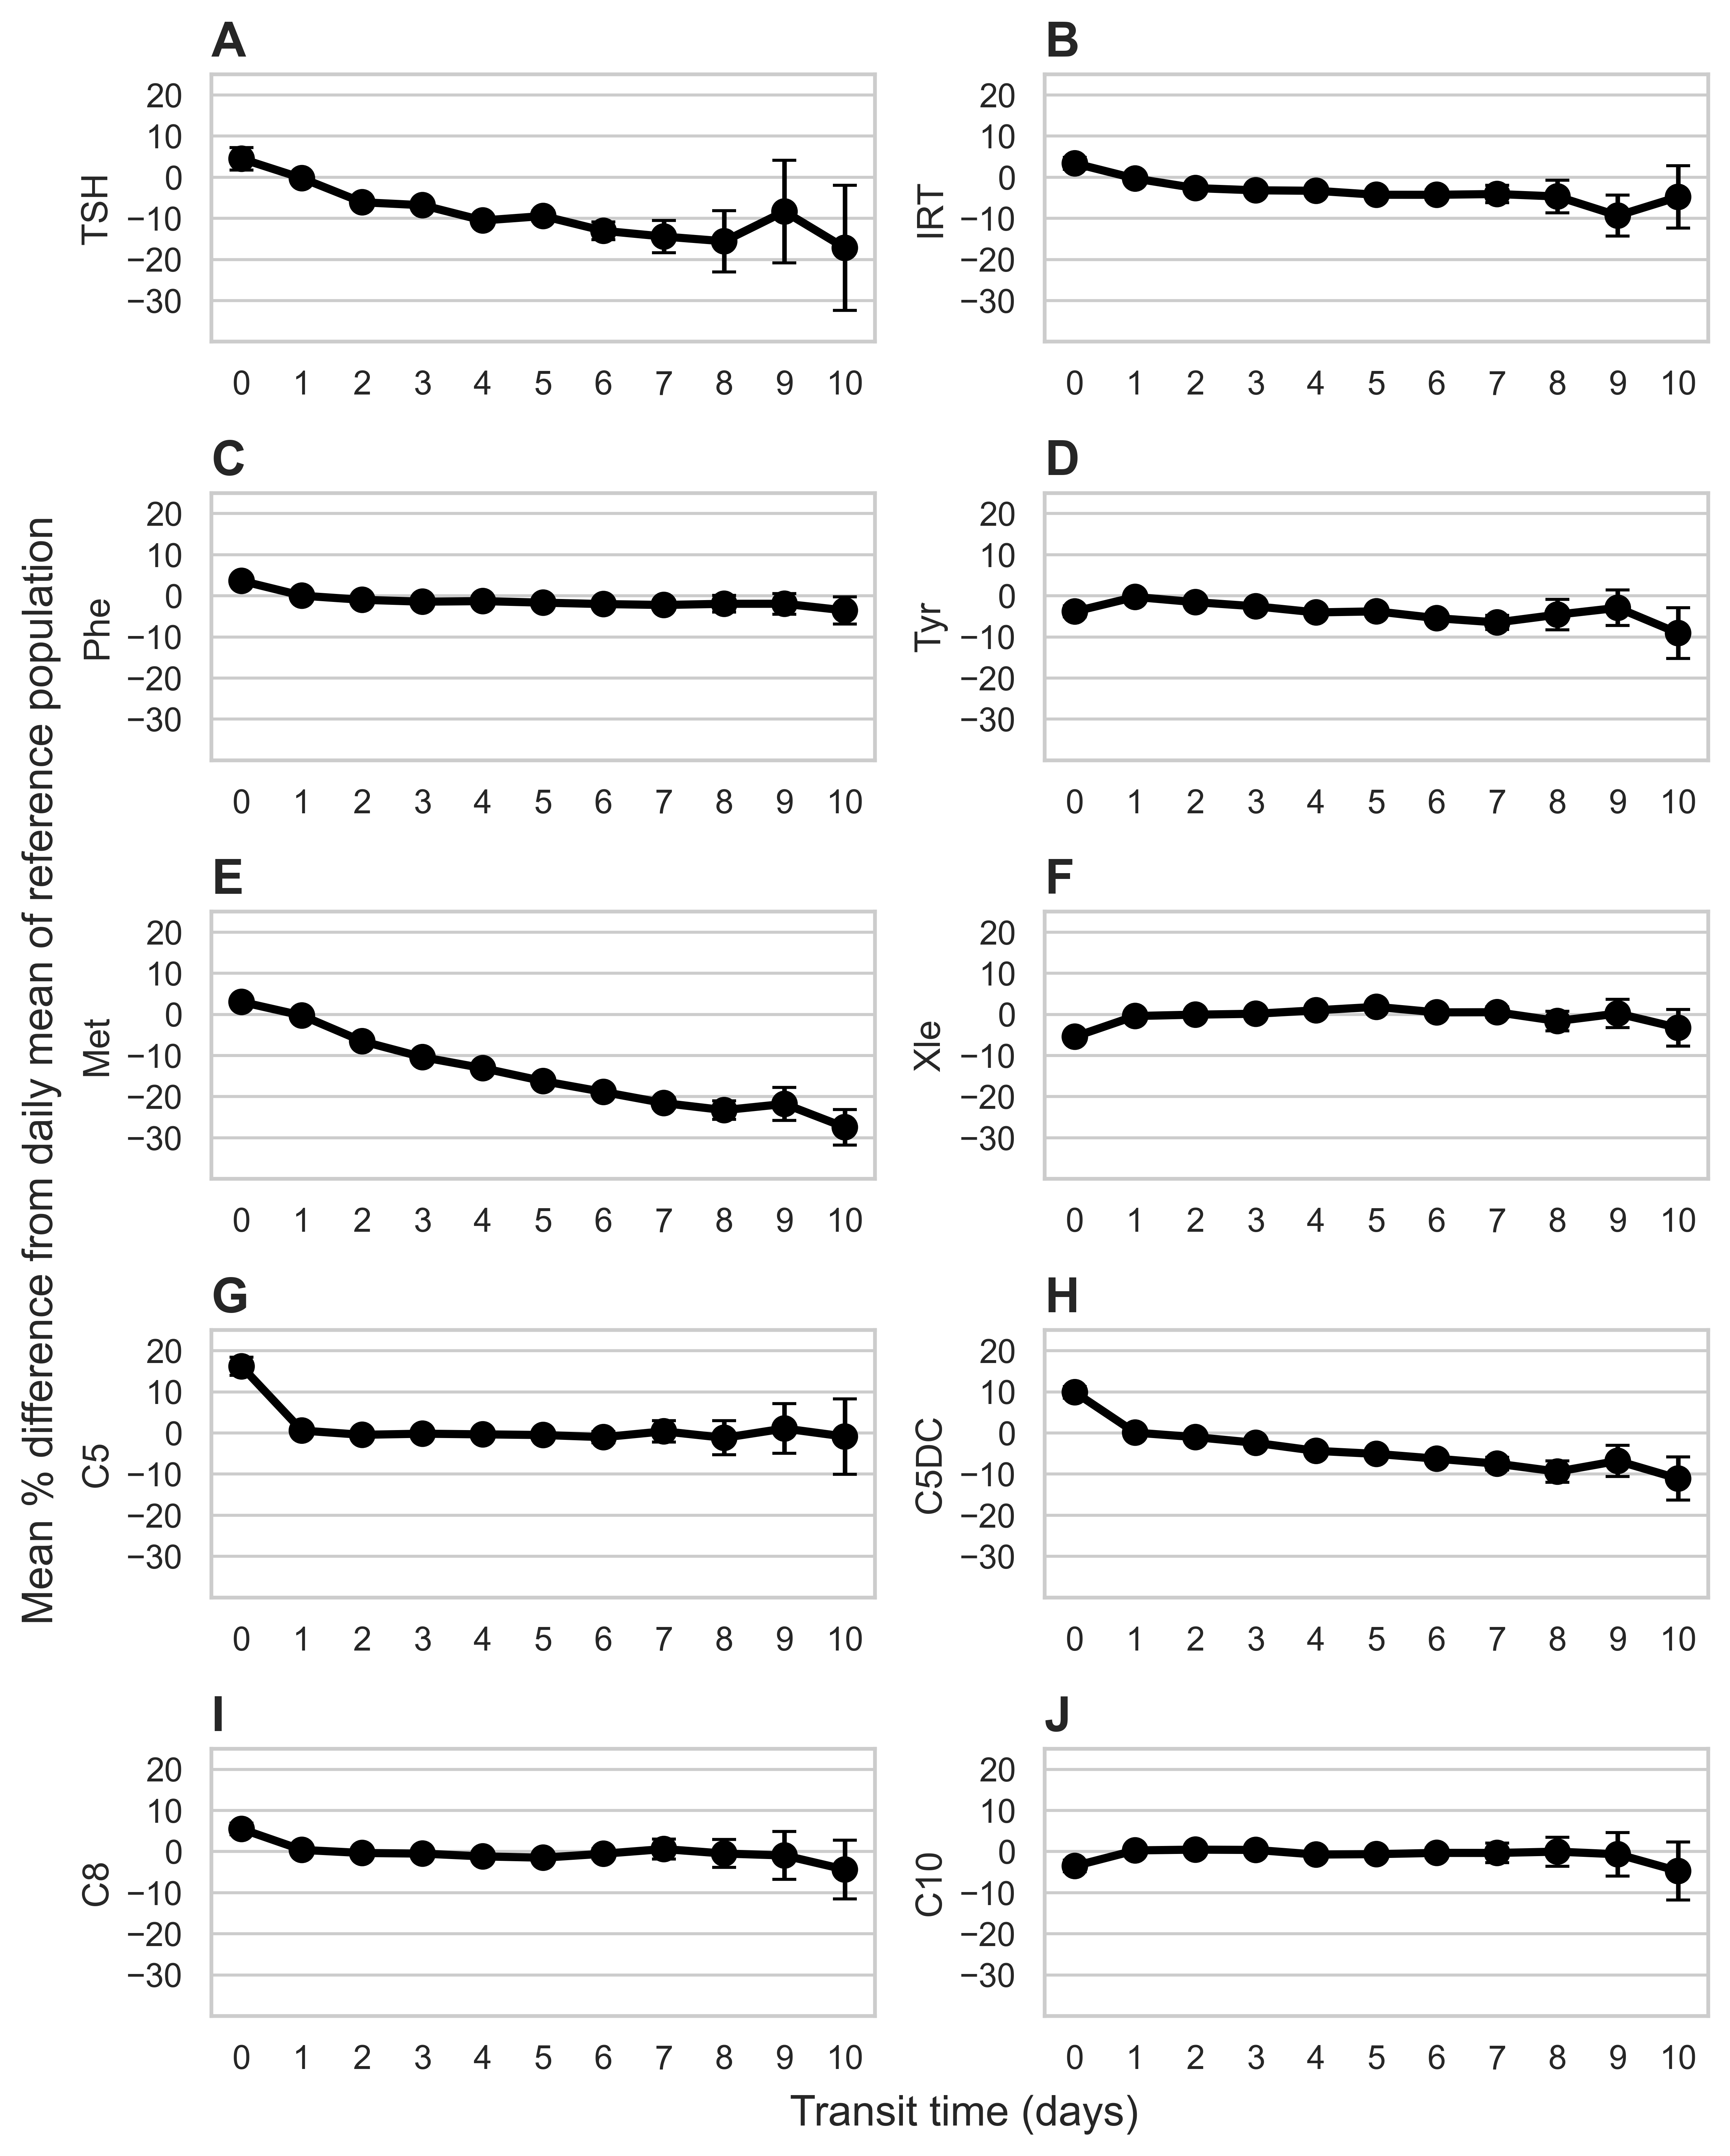

In [51]:
dfs = [tsh, irt, imd, imd, imd, imd, imd, imd, imd, imd]
analytes = ['TSH', 'IRT', 'Phe', 'Tyr', 'Met','Xleu','C5','C5DC','C8','C10']

fig, axes = plt.subplots(5, 2, figsize=(8, 10), dpi=600, sharex=False)

panel_labels = list(string.ascii_uppercase[:10])

for ax, df, analyte, label in zip(axes.flat, dfs, analytes, panel_labels):
    plot_mean_ci(df, analyte, col=f"{analyte.lower()}_%_diff_from_daily_mean", ax=ax, min_count=62)
    ax.set_title(label, loc='left', fontsize=16, fontweight='bold')
    
    # Display Xleu as Xle without changing the underlying data/code
    if analyte == "Xleu":
        ax.set_ylabel("Xle")

for ax in axes.flat:
    ax.set_ylim(-40, 25)
    
for ax in axes.flat:
    ax.set_xlabel("")
    
# Shared x label (bottom centre)
fig.text(0.55, 0.02, "Transit time (days)",
         ha="center", va="center", fontsize=14)

# Shared y label (left centre, rotated)
fig.text(0.02, 0.5, "Mean % difference from daily mean of reference population",
         ha="center", va="center",
         rotation="vertical", fontsize=14)

plt.tight_layout(rect=[0.02, 0.02, 1, 1])
plt.savefig('Figure2.jpg')
plt.show()


## Sensitivity/Subgroup analyses

### Exclude day 0

Define tables to exclude day 0

In [50]:
tshex0 = tsh[tsh['Days to receive'] != 0]
irtex0 = irt[irt['Days to receive'] != 0]
imdex0 = imd[imd['Days to receive'] != 0]

report_counts(tshdf=tshex0, irtdf=irtex0, imddf=imdex0)

TSH: 173080
IRT: 222266
IMD: 223767


In [51]:
combined_table_ex0 = ols_multivariate_combined({
    "TSH": tshex0,
    "IRT": irtex0,
    "IMD": imdex0
})

combined_table_ex0

,Dataframe,Analyte,N,R²,Days coef,ci_low,ci_high,Days coef (95% CI),Days p-value,Diameter coef (95% CI),Diameter p-value
0,TSH,TSH,173080,0.005,-2.472715,-2.769575,-2.175855,-2.47 (-2.77 - -2.18),<0.001,2.48 (2.15 - 2.81),<0.001
1,IRT,IRT,222266,0.006,-0.799974,-0.953448,-0.646500,-0.80 (-0.95 - -0.65),<0.001,2.44 (2.28 - 2.60),<0.001
2,IMD,C10,223767,<0.001,-0.217762,-0.369015,-0.066508,-0.22 (-0.37 - -0.07),0.005,-0.34 (-0.52 - -0.17),<0.001
3,IMD,C8,223767,<0.001,-0.330636,-0.474018,-0.187255,-0.33 (-0.47 - -0.19),<0.001,1.00 (0.83 - 1.17),<0.001
4,IMD,PHE,223767,0.007,-0.376549,-0.449543,-0.303555,-0.38 (-0.45 - -0.30),<0.001,1.46 (1.37 - 1.55),<0.001
5,IMD,TYR,223767,0.002,-1.001889,-1.125591,-0.878187,-1.00 (-1.13 - -0.88),<0.001,0.75 (0.60 - 0.89),<0.001
6,IMD,C5,223767,<0.001,-0.211221,-0.397731,-0.024711,-0.21 (-0.40 - -0.02),0.026,0.16 (-0.05 - 0.36),0.132
7,IMD,C5DC,223767,0.003,-1.334155,-1.468032,-1.200279,-1.33 (-1.47 - -1.20),<0.001,0.53 (0.38 - 0.68),<0.001
8,IMD,MET,223767,0.055,-3.779659,-3.901834,-3.657485,-3.78 (-3.90 - -3.66),<0.001,1.42 (1.31 - 1.52),<0.001
9,IMD,XLEU,223767,0.012,0.382587,0.286052,0.479122,0.38 (0.29 - 0.48),<0.001,2.49 (2.39 - 2.60),<0.001


In [52]:
tsh_median_ex0 = tshex0['TSH'].median()
irt_median_ex0 = irtex0['IRT'].median()
imd_medians_ex0 = imdex0[imd_cols].median()

# Make IMD median index uppercase
imd_medians_upper_ex0 = imd_medians_ex0.copy()
imd_medians_upper_ex0.index = imd_medians_upper_ex0.index.str.upper()

# 
combined_table_ex0['Median'] = combined_table_ex0['Analyte'].str.upper().map(imd_medians_upper_ex0)

combined_table_ex0.loc[
    combined_table_ex0['Dataframe'] == 'TSH', 'Median'
] = tsh_median_ex0

combined_table_ex0.loc[
    combined_table_ex0['Dataframe'] == 'IRT', 'Median'
] = irt_median_ex0

#Format medians appropriately
combined_table_ex0['Median'] = combined_table_ex0.apply(
    lambda r:
        f"{r['Median']:.1f}" if r['Analyte'].upper() in ['TSH','C5']
        else f"{r['Median']:.0f}" if r['Analyte'].upper() in ['IRT','PHE','MET','XLEU','TYR']
        else f"{r['Median']:.2f}" if r['Analyte'].upper() in ['C5DC','C8','C10']
        else f"{r['Median']}",
    axis=1
)

In [53]:
supp_table_ex0 = make_pub_table(combined_table_ex0)
supp_table_ex0.to_csv('supp_table_ex0.csv',index=False)
supp_table_ex0

,Analyte,N,Median,R²,% change in analyte concentration per additional day in transit,Transit time p value,% change in analyte concentration per mm increase in DBS diameter,DBS diameter p value
0,TSH,173080,1.3,0.005,-2.47 (-2.77 - -2.18),<0.001,2.48 (2.15 - 2.81),<0.001
1,IRT,222266,17,0.006,-0.80 (-0.95 - -0.65),<0.001,2.44 (2.28 - 2.60),<0.001
4,Phe,223767,55,0.007,-0.38 (-0.45 - -0.30),<0.001,1.46 (1.37 - 1.55),<0.001
5,Tyr,223767,96,0.002,-1.00 (-1.13 - -0.88),<0.001,0.75 (0.60 - 0.89),<0.001
8,Met,223767,16,0.055,-3.78 (-3.90 - -3.66),<0.001,1.42 (1.31 - 1.52),<0.001
9,Xle,223767,152,0.012,0.38 (0.29 - 0.48),<0.001,2.49 (2.39 - 2.60),<0.001
6,C5,223767,0.1,<0.001,-0.21 (-0.40 - -0.02),0.026,0.16 (-0.05 - 0.36),0.132
7,C5DC,223767,0.10,0.003,-1.33 (-1.47 - -1.20),<0.001,0.53 (0.38 - 0.68),<0.001
3,C8,223767,0.04,<0.001,-0.33 (-0.47 - -0.19),<0.001,1.00 (0.83 - 1.17),<0.001
2,C10,223767,0.07,<0.001,-0.22 (-0.37 - -0.07),0.005,-0.34 (-0.52 - -0.17),<0.001


## Seasonal variation by calendar month

Calculate OLS analysis for each month

In [54]:
monthly_results = {}

for month in range(1, 13):
    tsh_month = tsh[tsh["Date Rec'd"].dt.month == month]
    irt_month = irt[irt["Date Rec'd"].dt.month == month]
    imd_month = imd[imd["Date Rec'd"].dt.month == month]

    monthly_results[month] = ols_multivariate_combined({
        "TSH": tsh_month,
        "IRT": irt_month,
        "IMD": imd_month
    })
            
    monthly_results[month]['month'] = month


Concatenate dataframes

In [55]:
monthly_results_df = pd.concat(monthly_results[i] for i in range (1,13))

Calculate total samples included

In [56]:
print("TSH: " + str(sum(monthly_results_df[monthly_results_df['Analyte'] == 'TSH']['N'])))
print("IRT: " + str(sum(monthly_results_df[monthly_results_df['Analyte'] == 'IRT']['N'])))
print("IMD: " + str(sum(monthly_results_df[monthly_results_df['Analyte'] == 'PHE']['N'])))

TSH: 175774
IRT: 225602
IMD: 227032


In [57]:
monthly_results_df.head()

,Dataframe,Analyte,N,R²,Days coef,ci_low,ci_high,Days coef (95% CI),Days p-value,Diameter coef (95% CI),Diameter p-value,month
0,TSH,TSH,13014,0.008,-3.289056,-4.211058,-2.367054,-3.29 (-4.21 - -2.37),<0.001,2.94 (1.63 - 4.25),<0.001,1
1,IRT,IRT,17030,0.008,-0.780008,-1.271035,-0.288981,-0.78 (-1.27 - -0.29),0.002,3.05 (2.48 - 3.61),<0.001,1
2,IMD,C10,17519,<0.001,-0.250517,-0.753229,0.252195,-0.25 (-0.75 - 0.25),0.329,-0.15 (-0.80 - 0.51),0.658,1
3,IMD,C8,17519,<0.001,-0.244338,-0.717004,0.228328,-0.24 (-0.72 - 0.23),0.311,0.86 (0.17 - 1.55),0.015,1
4,IMD,PHE,17519,0.006,-0.221550,-0.462829,0.019729,-0.22 (-0.46 - 0.02),0.072,1.33 (1.00 - 1.66),<0.001,1


Plot seasonal variation for all analytes

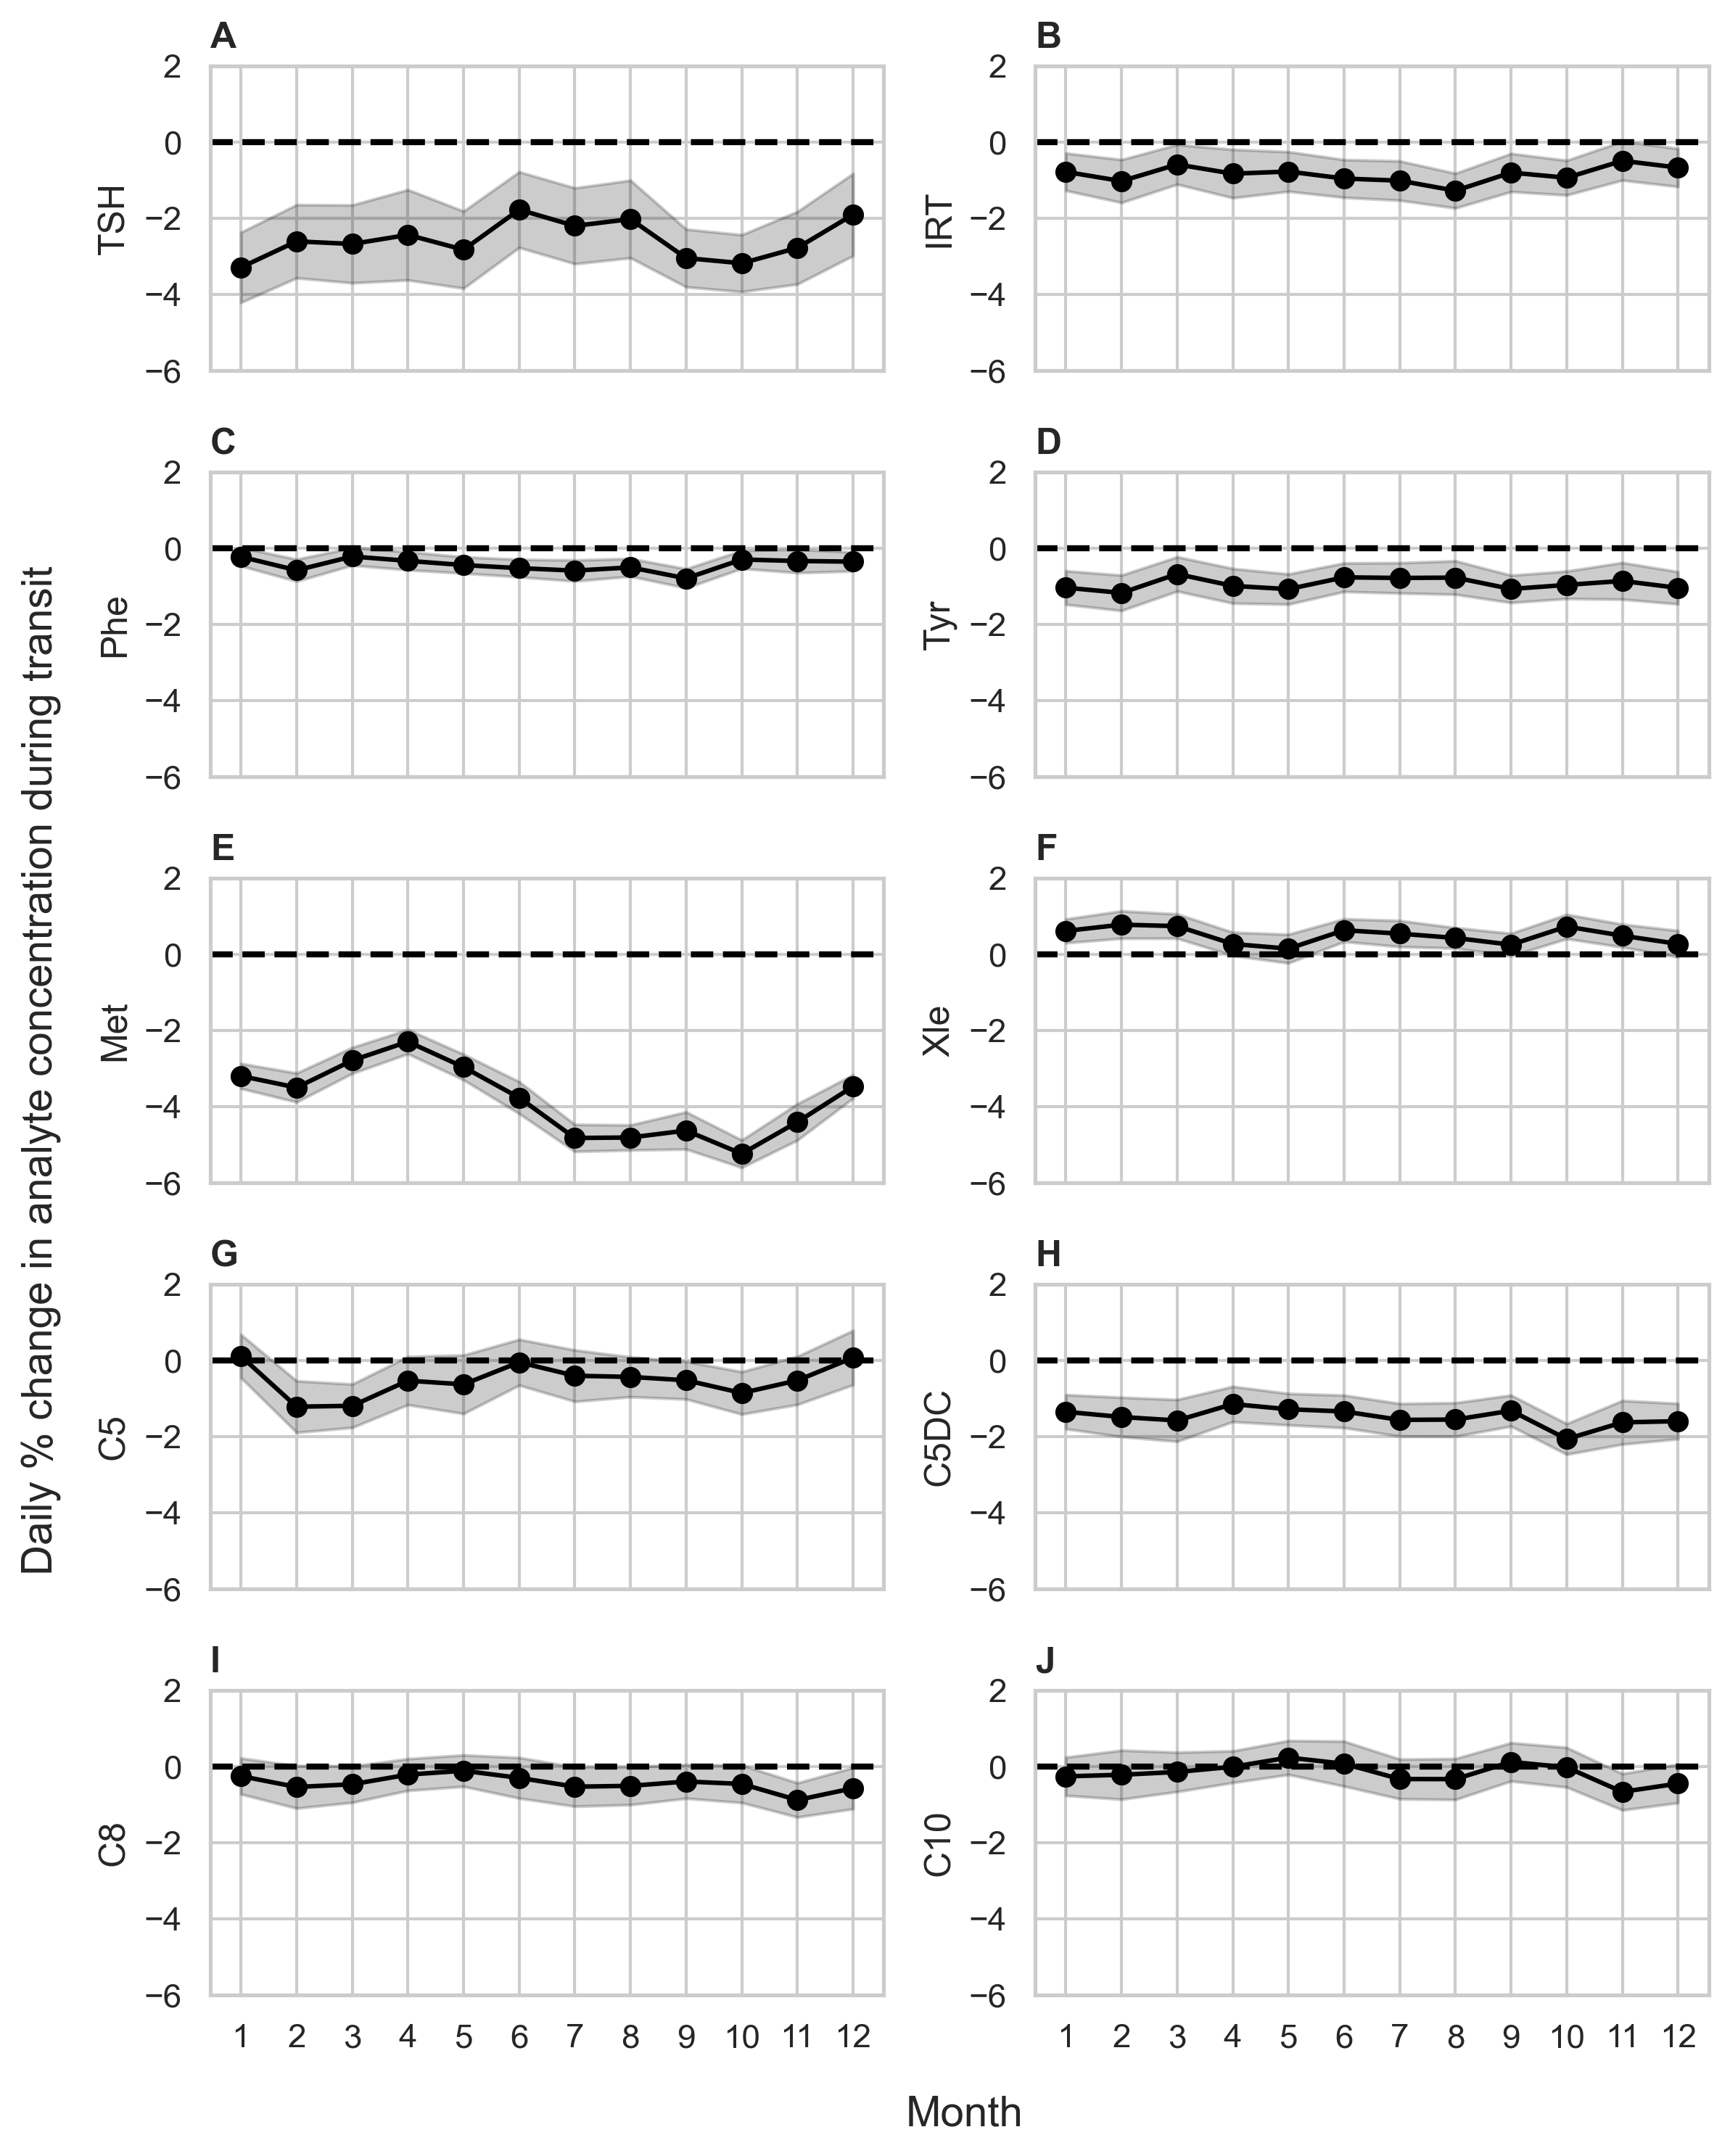

In [58]:
analytes = ['TSH', 'IRT', 'PHE', 'TYR', 'MET','XLEU','C5','C5DC','C8','C10']
analyte_labels = ['TSH', 'IRT', 'Phe', 'Tyr', 'Met','Xle','C5','C5DC','C8','C10']

fig, axes = plt.subplots(5, 2, figsize=(8,10), dpi=300, sharex=True)
axes = axes.flatten()  # Flatten for easy indexing

# Create panel labels
panel_labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ... ]


for i, analyte in enumerate(analytes):
    ax = axes[i]

    # Filter data
    df = monthly_results_df[monthly_results_df['Analyte'] == analyte].copy()

    # Plot coefficient with CI
    ax.plot(df['month'], df['Days coef'], marker='o', linestyle='-', color='black')
    ax.fill_between(df['month'], df['ci_low'], df['ci_high'], alpha=0.2, color='black')
    ax.axhline(0, linestyle='--', linewidth=2, color='black')
    ax.set_xticks(df['month'])
    ax.set_ylabel(analyte_labels[i])
    ax.set_ylim(-6,2)
    ax.set_title(panel_labels[i], loc='left', fontweight='bold')
    
# Shared x label (bottom centre)
fig.text(0.55, 0.02, "Month",
         ha="center", va="center", fontsize=14)

# Shared y label (left centre, rotated)
fig.text(0.02, 0.5, "Daily % change in analyte concentration during transit",
         ha="center", va="center",
         rotation="vertical", fontsize=14)

plt.tight_layout(rect=[0.03, 0.03, 1, 1])


See raw values for methionine

In [59]:
monthly_results_df[monthly_results_df['Analyte'] == 'MET']

,Dataframe,Analyte,N,R²,Days coef,ci_low,ci_high,Days coef (95% CI),Days p-value,Diameter coef (95% CI),Diameter p-value,month
8,IMD,MET,17519,0.042,-3.191045,-3.518628,-2.863463,-3.19 (-3.52 - -2.86),<0.001,1.53 (1.15 - 1.91),<0.001,1
8,IMD,MET,16456,0.043,-3.494307,-3.874975,-3.113640,-3.49 (-3.87 - -3.11),<0.001,1.34 (0.95 - 1.73),<0.001,2
8,IMD,MET,17370,0.032,-2.782016,-3.123125,-2.440907,-2.78 (-3.12 - -2.44),<0.001,1.47 (1.05 - 1.89),<0.001,3
8,IMD,MET,18553,0.027,-2.289874,-2.607091,-1.972657,-2.29 (-2.61 - -1.97),<0.001,1.31 (0.93 - 1.69),<0.001,4
8,IMD,MET,19701,0.039,-2.957464,-3.293466,-2.621462,-2.96 (-3.29 - -2.62),<0.001,1.26 (0.92 - 1.60),<0.001,5
8,IMD,MET,19410,0.054,-3.759800,-4.178792,-3.340809,-3.76 (-4.18 - -3.34),<0.001,1.27 (0.90 - 1.64),<0.001,6
8,IMD,MET,20591,0.082,-4.818300,-5.173040,-4.463559,-4.82 (-5.17 - -4.46),<0.001,1.76 (1.40 - 2.11),<0.001,7
8,IMD,MET,20291,0.088,-4.806089,-5.135532,-4.476646,-4.81 (-5.14 - -4.48),<0.001,1.59 (1.25 - 1.92),<0.001,8
8,IMD,MET,20622,0.083,-4.623167,-5.111703,-4.134631,-4.62 (-5.11 - -4.13),<0.001,1.53 (1.21 - 1.85),<0.001,9
8,IMD,MET,21074,0.098,-5.233347,-5.594101,-4.872593,-5.23 (-5.59 - -4.87),<0.001,1.64 (1.33 - 1.96),<0.001,10


# Relationship with local meteriorlogical data

Load data obtained from Met Office https://www.metoffice.gov.uk/research/climate/maps-and-data/historic-station-data

In [60]:
cambridge_niab = pd.read_csv('data/cambridgeniab_cleaned.csv')

In [61]:
cambridge_niab

,yyyy,mm,tmax,tmin,af,rain
0,2015,4,15.0,4.1,0,20.2
1,2015,5,16.5,7.5,2,42.2
2,2015,6,20.3,9.5,0,19.0
3,2015,7,22.5,12.3,0,78.8
4,2015,8,22.2,12.7,0,47.4
...,...,...,...,...,...,...
122,2025,6,24.8,13.0,0,25.4
123,2025,7,24.9,14.3,0,44.8
124,2025,8,24.5,13.0,0,16.0
125,2025,9,20.2,10.0,0,38.6


Define a function to plot seasonal variation, population statistics and meteriorlogical data

In [62]:
def plot_monthly_summary(df_noexc,analyte,ylim_stability=(-6,2),ylim_conc=(0,35),filename=None):
    df_noexc['month'] = df_noexc["Date Rec'd"].dt.month

    # --- Monthly summaries ---
    monthly_max_temp = cambridge_niab.groupby('mm')['tmax'].mean()
    monthly_min_temp = cambridge_niab.groupby('mm')['tmin'].mean()
    monthly_rainfall = cambridge_niab.groupby('mm')['rain'].mean()

    #population statistics
    median = df_noexc.groupby('month')[analyte].median()
    per1 = df_noexc.groupby('month')[analyte].quantile(0.01)
    per25 = df_noexc.groupby('month')[analyte].quantile(0.25)
    per75 = df_noexc.groupby('month')[analyte].quantile(0.75)
    per99 = df_noexc.groupby('month')[analyte].quantile(0.99)

    # --- Coefficients dataframe ---
    df = monthly_results_df[monthly_results_df['Analyte'] == analyte.upper()].copy()

    df[['coef', 'ci_low', 'ci_high']] = (
        df['Days coef (95% CI)']
        .str.extract(r'([-\d\.]+)\s+\(([-\d\.]+)\s+-\s+([-\d\.]+)\)')
        .astype(float))

    # --- Create multi-panel figure ---
    fig, axes = plt.subplots(nrows=4,ncols=1,figsize=(8, 12),dpi=600,sharex=True)

    # Stability
    axes[0].plot(df['month'], df['coef'], marker='o', linestyle='-', color='black')
    axes[0].fill_between(df['month'],df['ci_low'],df['ci_high'],alpha=0.2,color='black')
    axes[0].set_ylabel(f"{analyte}\n% change per day")
    axes[0].set_title("A", loc='left')
    axes[0].set_ylim(ylim_stability)
    
    # Concentration
    axes[1].plot(median.index, median, marker='o', linestyle='-', color='black')
    axes[1].fill_between(df['month'], per25, per75, alpha=0.4, color='black')
    axes[1].fill_between(df['month'], per1, per99, alpha=0.2, color='black')
    axes[1].set_ylabel(f"{analyte} (μmol/L)")
    axes[1].set_title("B", loc='left')
    axes[1].set_ylim(ylim_conc)

    # Rainfall
    axes[2].plot(monthly_rainfall.index, monthly_rainfall.values, marker='o', linestyle='--', color='black')
    axes[2].set_ylabel("Average\nrainfall (mm)")
    axes[2].set_title("C", loc='left')
    axes[2].set_ylim(0,80)

    # Temperature
    axes[3].plot(monthly_max_temp.index, monthly_max_temp.values, marker='o', linestyle='-', label='Maximum', color='black')
    axes[3].plot(monthly_min_temp.index, monthly_min_temp.values, marker='o', linestyle='--',label='Minimum', color='black')
    axes[3].set_ylabel("Average minimum &\nmaximum temperature (°C)")
    axes[3].set_xlabel("Month")
    axes[3].set_xticks(df['month'])
    axes[3].set_title("D", loc='left')
    axes[3].set_ylim(0,30)
    axes[3].legend()

    # --- Layout ---
    plt.tight_layout()
    
    if filename is not None:
        plt.savefig(filename)
        
    plt.show()

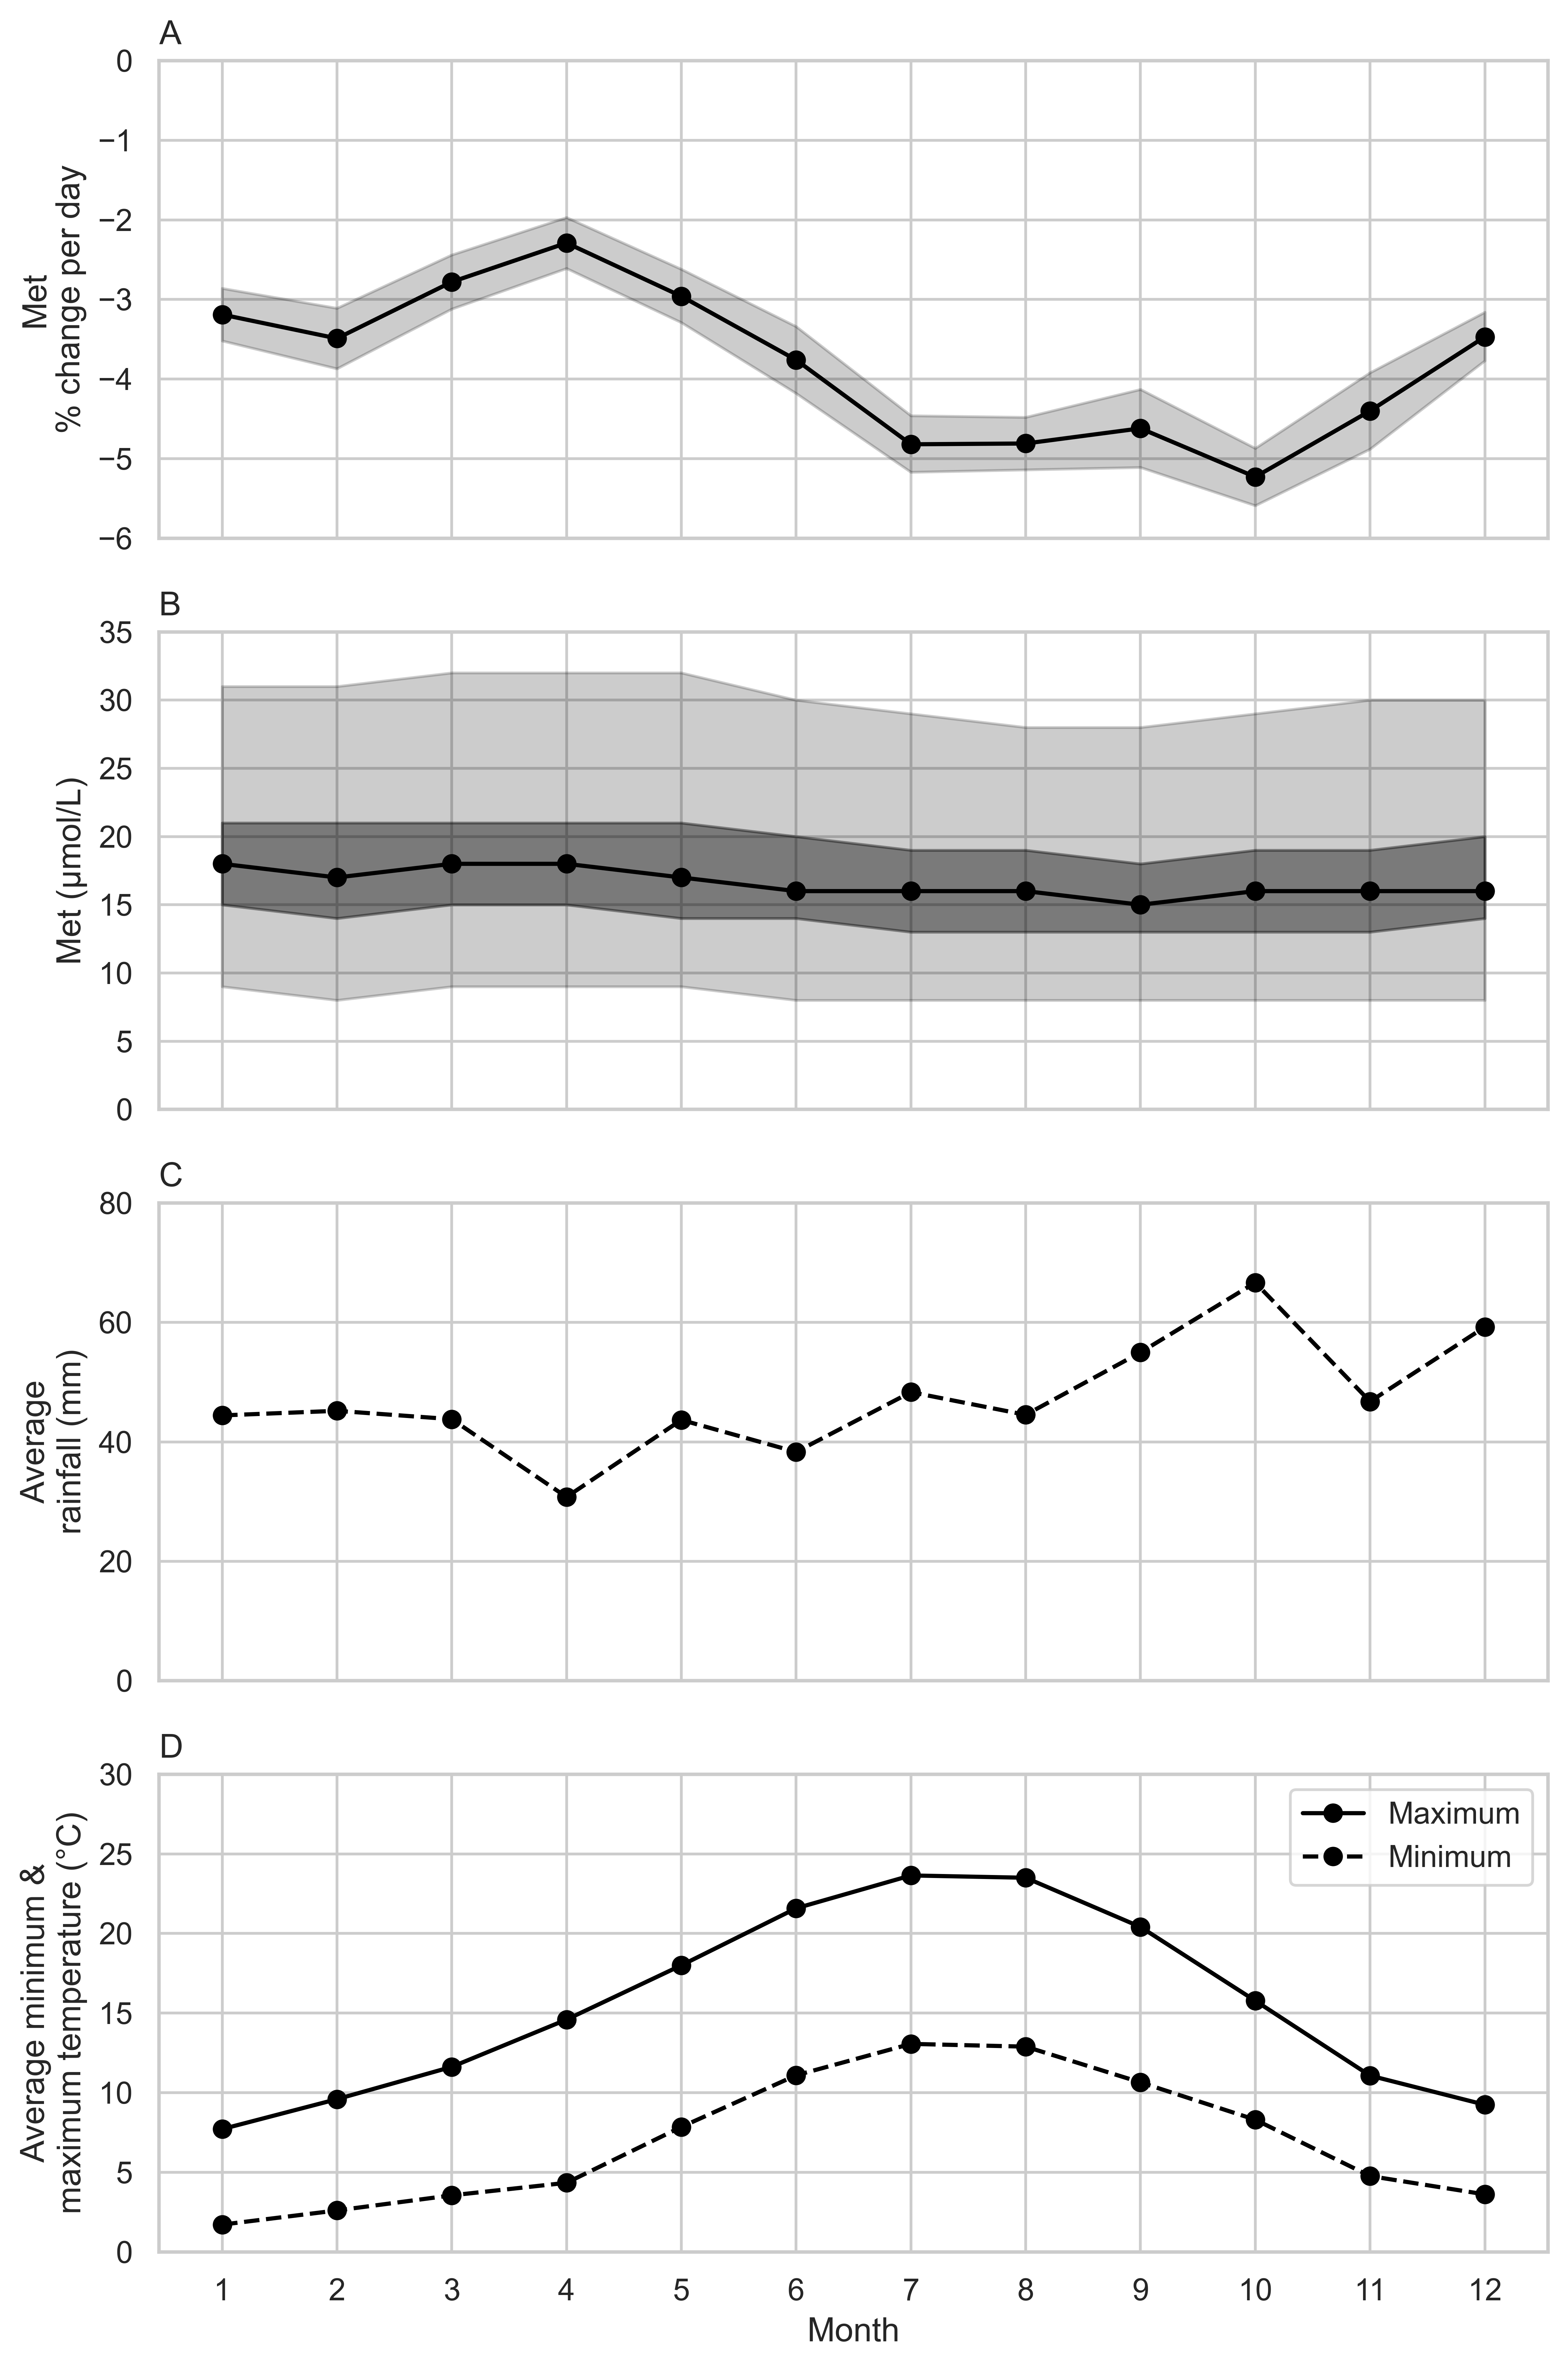

In [63]:
plot_monthly_summary(imd_noexc,"Met",ylim_stability=(-6,0),ylim_conc=(0,35),filename='Figure3.jpg')

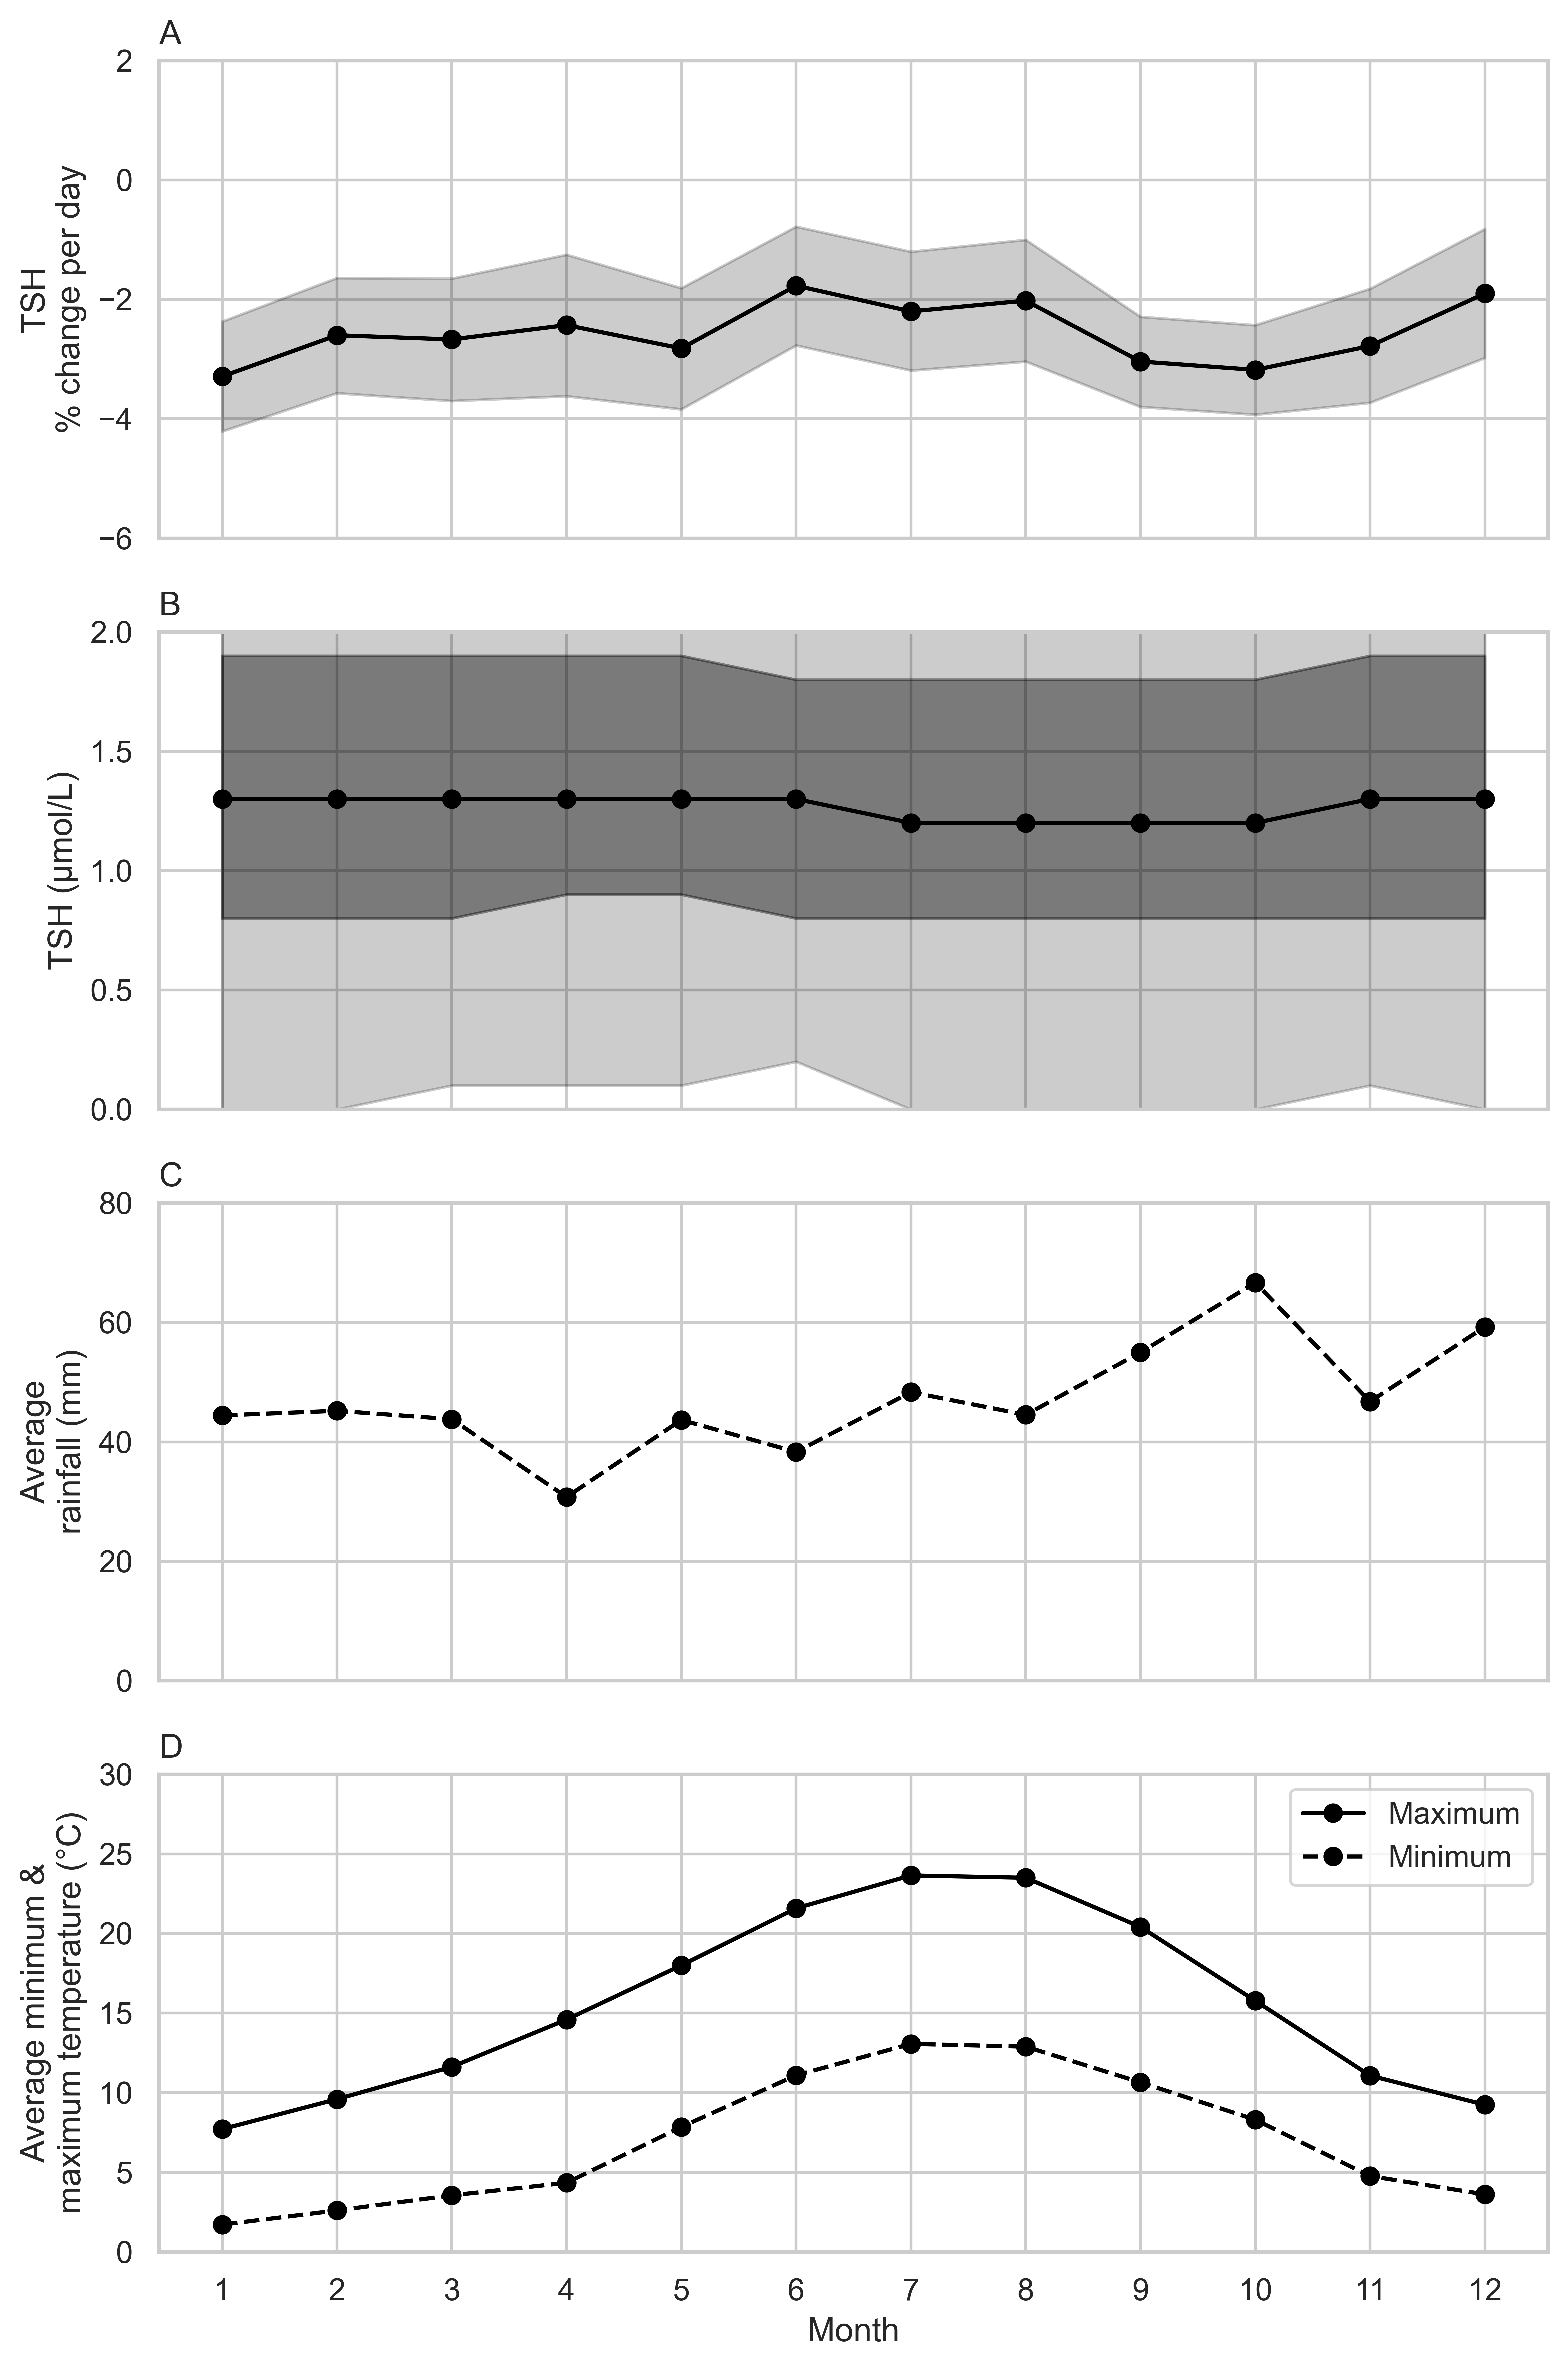

In [64]:
plot_monthly_summary(tsh_noexc,"TSH",ylim_stability=(-6,2),ylim_conc=(0,2))

Methionine population distributions

In [65]:
imd_noexc.groupby('month')['Met'].describe(percentiles=[0.01,0.05,0.25,0.50,0.75,0.95,0.99])

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
month,,,,,,,,,,,,
1,19362.0,18.037444,4.761693,3.0,9.0,11.0,15.0,18.0,21.0,26.0,31.0,76.0
2,18377.0,17.762910,4.848679,1.0,8.0,11.0,14.0,17.0,21.0,26.0,31.0,58.0
3,20066.0,18.361258,5.015581,3.0,9.0,11.0,15.0,18.0,21.0,27.0,32.0,86.0
4,21265.0,18.200893,4.820644,3.0,9.0,11.0,15.0,18.0,21.0,27.0,32.0,66.0
5,22344.0,17.790951,4.824144,3.0,9.0,11.0,14.0,17.0,21.0,26.0,32.0,77.0
6,22386.0,16.887519,4.588800,0.0,8.0,10.0,14.0,16.0,20.0,25.0,30.0,83.0
7,23163.0,16.452748,4.539920,3.0,8.0,10.0,13.0,16.0,19.0,24.0,29.0,55.0
8,22866.0,16.028601,4.409655,2.0,8.0,10.0,13.0,16.0,19.0,24.0,28.0,53.0
9,23082.0,15.637380,4.305886,2.0,8.0,10.0,13.0,15.0,18.0,23.0,28.0,65.0


## Compare distribution by transit time

In [66]:
imd_noexc.groupby('Days to receive')['Met'].describe(percentiles=[0.01,0.05,0.25,0.50,0.75,0.95,0.99])

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Days to receive,,,,,,,,,,,,
0,3789.0,18.880707,5.402932,3.0,8.00,11.00,15.00,18.0,22.00,28.00,34.00,83.0
1,72430.0,18.227820,4.810639,0.0,9.00,11.00,15.00,18.0,21.00,27.00,32.00,173.0
2,75941.0,17.067434,4.610087,2.0,8.00,11.00,14.00,17.0,20.00,25.00,30.00,137.0
3,48506.0,16.419165,4.576198,2.0,8.00,10.00,13.00,16.0,19.00,25.00,29.00,86.0
4,33181.0,15.915855,4.523481,2.0,7.00,10.00,13.00,15.0,19.00,24.00,29.00,70.0
5,15376.0,15.477367,4.421442,3.0,7.00,9.00,12.00,15.0,18.00,23.00,28.00,49.0
6,4943.0,15.341291,4.521392,2.0,7.00,9.00,12.00,15.0,18.00,23.00,28.00,38.0
7,1458.0,14.927298,4.676222,5.0,7.00,8.00,12.00,14.0,18.00,23.00,28.43,44.0
8,426.0,14.544601,4.697347,4.0,6.25,8.00,11.00,14.0,17.00,22.00,29.00,36.0


In [67]:
imd_cols

['C10', 'C8', 'Phe', 'Tyr', 'C5', 'C5DC', 'Met', 'Xleu']

(0.0, 50.0)

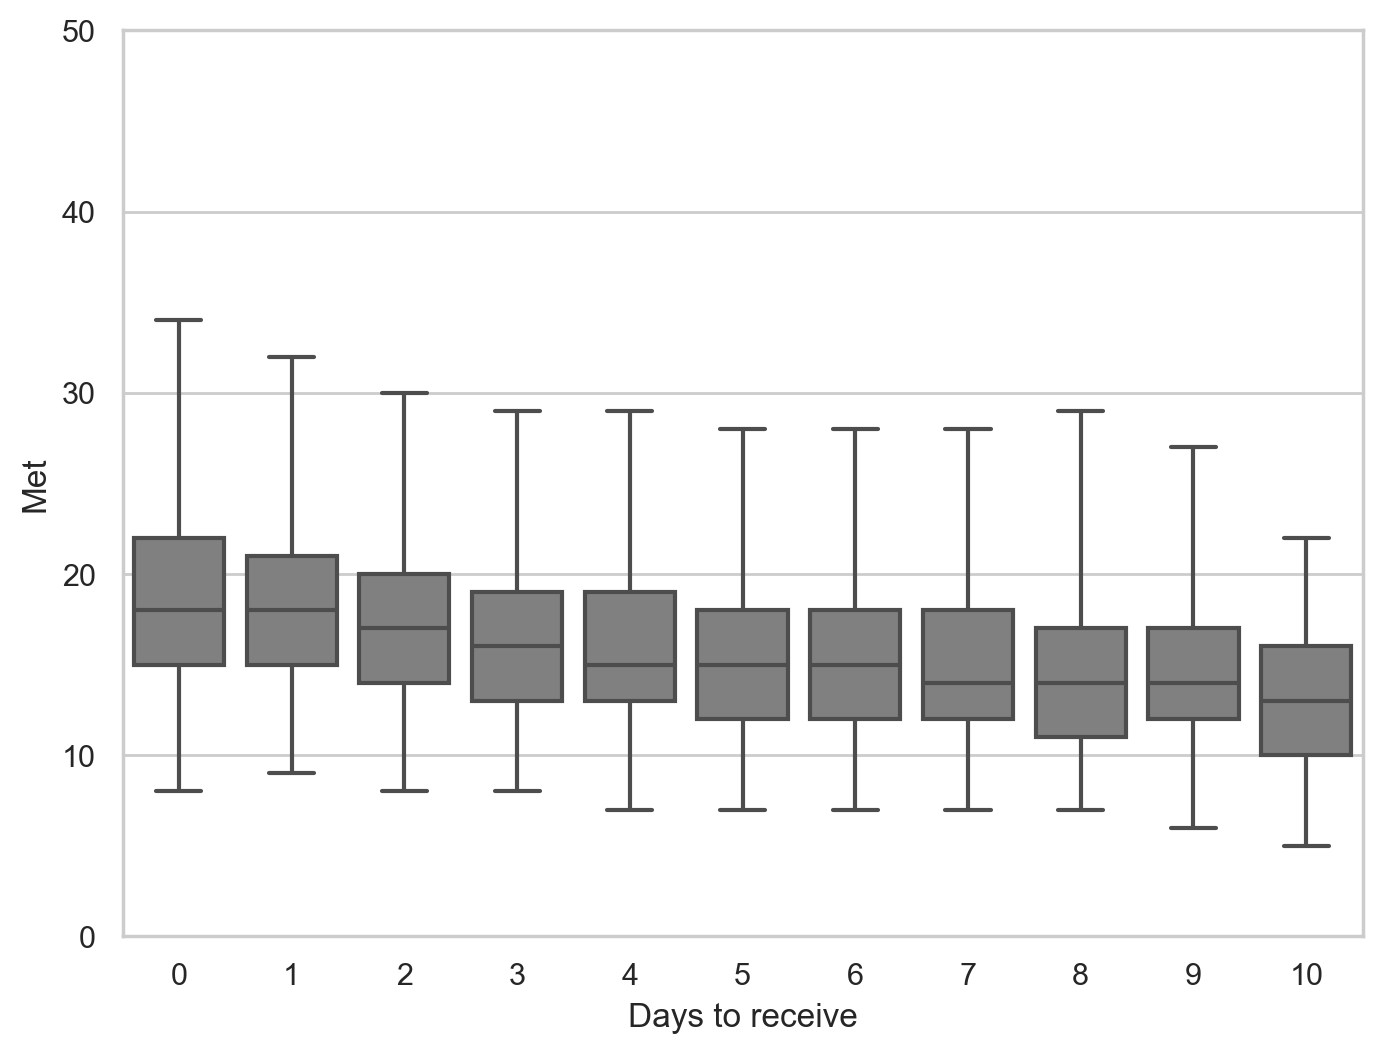

In [68]:
plt.figure(figsize=(8,6), dpi=200)
sns.boxplot(data=imd_noexc[imd_noexc['Days to receive'] <= 10],x='Days to receive',y='Met',showfliers=False, whis=(1,99), color='gray')

plt.ylim(0,50)

(0.0, 10.0)

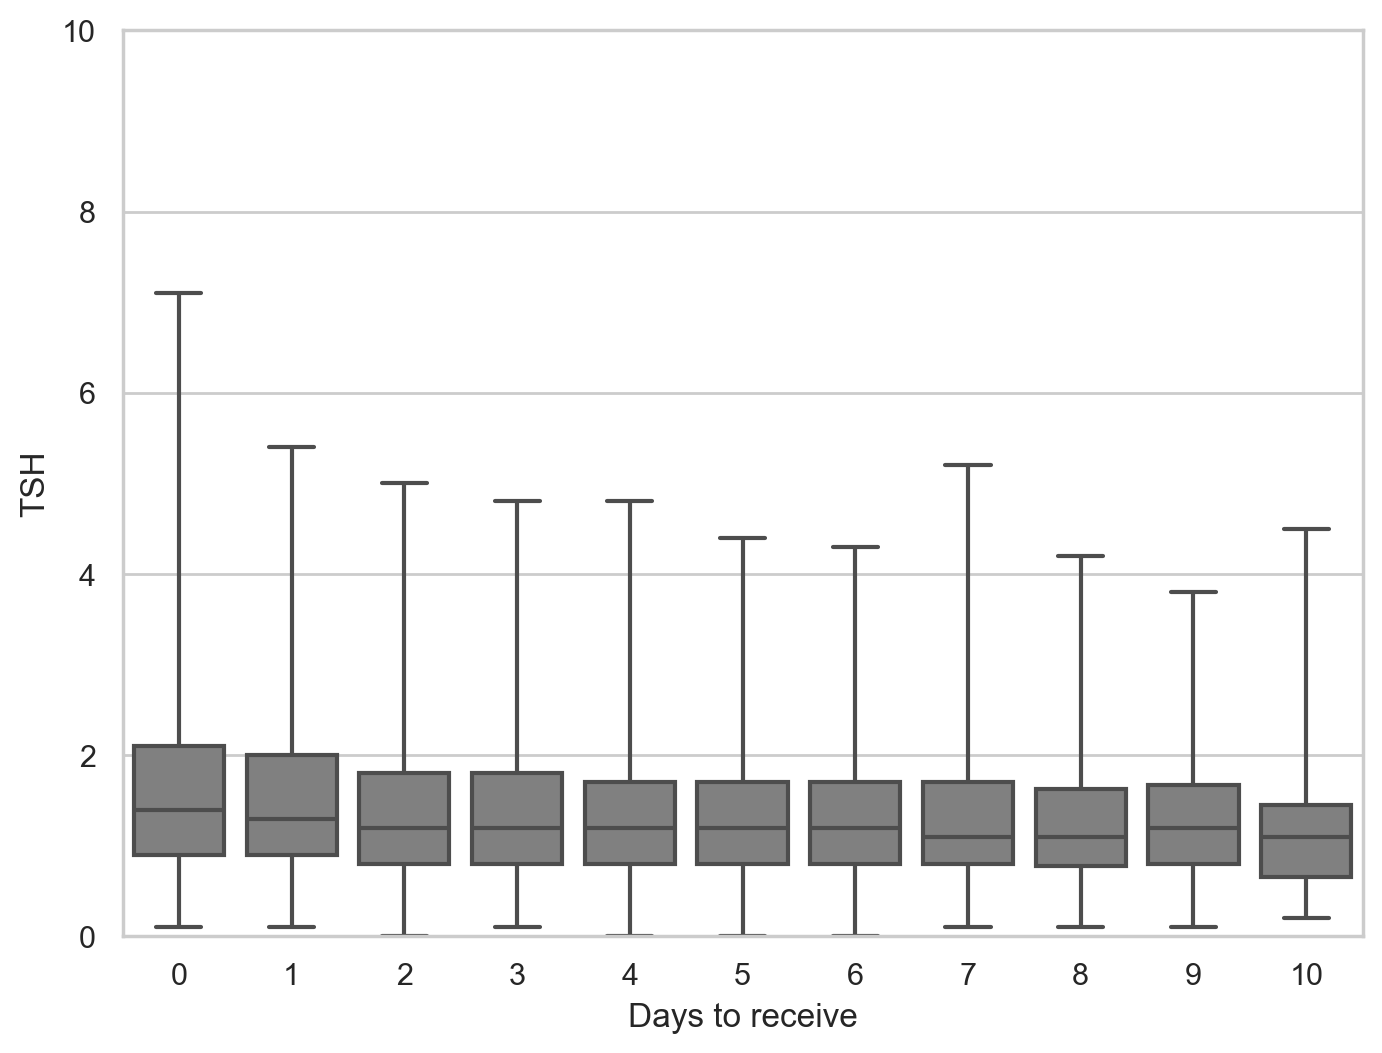

In [69]:
plt.figure(figsize=(8,6), dpi=200)
sns.boxplot(data=tsh_noexc[tsh_noexc['Days to receive'] <= 10],x='Days to receive',y='TSH',showfliers=False, whis=(1,99), color='gray')

plt.ylim(0,10)

(0.0, 60.0)

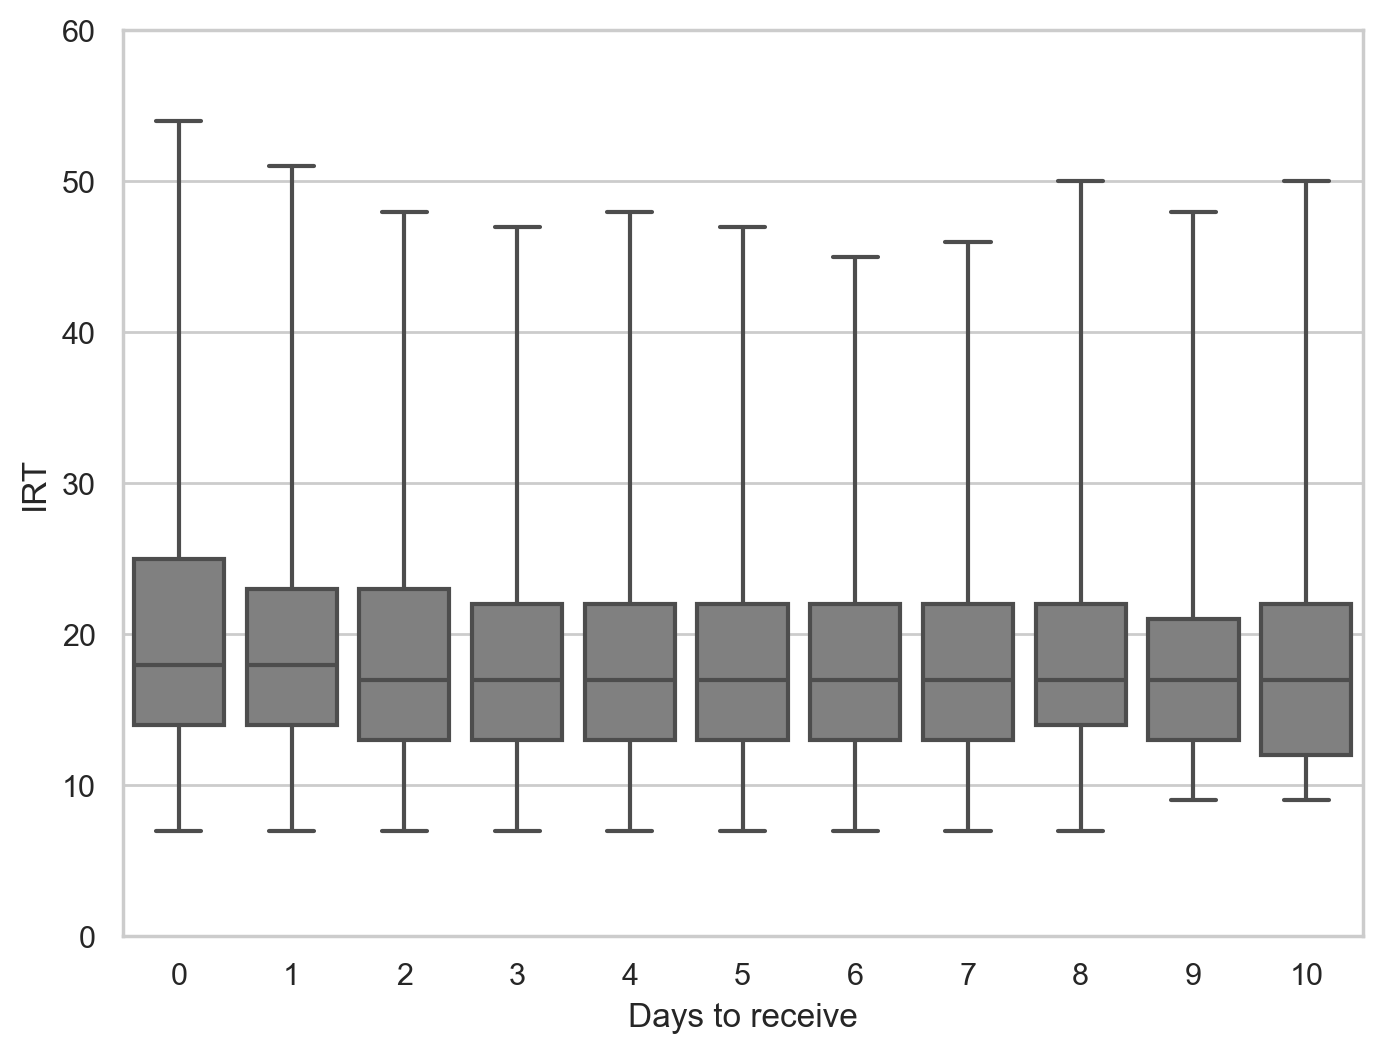

In [70]:
plt.figure(figsize=(8,6), dpi=200)
sns.boxplot(data=irt_noexc[irt_noexc['Days to receive'] <= 10],x='Days to receive',y='IRT',showfliers=False, whis=(1,99), color='gray')

plt.ylim(0,60)

## Data by month and year

Calculate OLS for each month in the dataset

In [71]:
# List of dataframes to process
dfs = [imd, tsh, irt]

# Store results
year_month_dfs = []

for df in dfs:
    for month in df['year_month'].sort_values().unique():
        subset = df[df['year_month'] == month]
        if subset.empty:
            continue
        
        # Run your OLS function
        stats = ols_multivariate(df=subset)
        
        # Add year_month, year, month columns
        stats['year_month'] = month
        stats['year'] = month.year
        stats['month'] = month.month
        
        year_month_dfs.append(stats)

# Concatenate all results
year_month_dataframe = pd.concat(year_month_dfs, ignore_index=True)

In [72]:
def plot_year_month_stats(df_noexc,analyte,ylim_stability=(-10,0),ylim_conc=(0,35)):
    
    analyte_summary = year_month_dataframe[
    (year_month_dataframe['Analyte'] == analyte.lower()) & 
    (year_month_dataframe['Predictor'] == 'Days to receive')].copy()
    
    # Ensure year_month column is datetime
    analyte_summary['year_month_dt'] = analyte_summary['year_month'].dt.to_timestamp()
    
    # Sort chronologically
    analyte_summary = analyte_summary.sort_values('year_month_dt')
    
    # Find the month with maximum coefficient
    max_row = analyte_summary.loc[analyte_summary['Coefficient'].idxmax()]
    max_month = max_row['year_month_dt']

    # Find the month with minimum coefficient
    min_row = analyte_summary.loc[analyte_summary['Coefficient'].idxmin()]
    min_month = min_row['year_month_dt']


    # Compute monthly concentration statistics
    median = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))[analyte].median()
    p25 = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))[analyte].quantile(0.25)
    p75 = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))[analyte].quantile(0.75)
    p1 = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))[analyte].quantile(0.01)
    p99 = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))[analyte].quantile(0.99)

    # Computer transit time statistics
    trans_med = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))['Days to receive'].mean()
    trans_p25 = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))['Days to receive'].quantile(0.25)
    trans_p75 = df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))['Days to receive'].quantile(0.75)
    
    # Convert PeriodIndex to datetime for plotting
    imd_months_dt = median.index.to_timestamp()

    # Prepare weather data (Panels C & D)
    # Convert to datetime
    cambridge_niab['year_month_dt'] = pd.to_datetime(
        cambridge_niab['yyyy'].astype(str) + '-' +
        cambridge_niab['mm'].astype(str).str.zfill(2) + '-01'
    )
    monthly_max_temp = cambridge_niab.groupby('year_month_dt')['tmax'].mean()
    monthly_min_temp = cambridge_niab.groupby('year_month_dt')['tmin'].mean()
    monthly_rainfall = cambridge_niab.groupby('year_month_dt')['rain'].mean()
    
  
    # Create 5-panel figure
    fig, axes = plt.subplots(nrows=5,ncols=1,figsize=(8, 12),dpi=300,sharex=True)

    # Panel A: Stability
    axes[0].plot(analyte_summary['year_month_dt'],analyte_summary['Coefficient'],marker='',linestyle='-',color='black')
    axes[0].fill_between(analyte_summary['year_month_dt'],analyte_summary['95% CI Lower'],analyte_summary['95% CI Upper'],
        alpha=0.2,color='black')
    axes[0].set_ylabel(f"{analyte}\n% change per day")
    axes[0].set_title("A", loc='left')
    axes[0].set_ylim(ylim_stability)

    # Panel B: Concentration
    axes[1].plot(imd_months_dt, median, marker='',linestyle='-',color='black')
    axes[1].fill_between(imd_months_dt, p25, p75,alpha=0.4, color='black')
    axes[1].fill_between(imd_months_dt, p1, p99, alpha=0.2,color='black')
    axes[1].set_ylabel(f"{analyte} (μmol/L)")
    axes[1].set_title("B", loc='left')
    axes[1].set_ylim(ylim_conc)
                                 
    # Panel C: Transit time
    #axes[2].plot(imd_months_dt, trans_med, marker='',linestyle='-',color='black')
    #axes[2].fill_between(imd_months_dt, trans_p25, trans_p75,alpha=0.4, color='black')

    # Bin the days: 0,1,2,3,...,6,7+
    bins = [-0.1,0,1,2,3, 4, np.inf]  # -0.1 so 0 is included
    labels = ['0','1','2','3','4','4+']
    df_noexc['Days_bin'] = pd.cut(df_noexc['Days to receive'], bins=bins, labels=labels, right=True)

    # Compute monthly proportions
    monthly_counts = (
        df_noexc.groupby(df_noexc["Date Rec'd"].dt.to_period('M'))['Days_bin']
        .value_counts(normalize=True)  # proportion
        .unstack(fill_value=0)
        .sort_index()
    )

    # Convert PeriodIndex to datetime for plotting
    months_dt = monthly_counts.index.to_timestamp()

    # Plot stacked area chart
    axes[2].stackplot(
        months_dt,
        [monthly_counts[col] for col in labels],
        labels=labels,
        colors=plt.cm.Greys(np.linspace(0,1,len(labels))),
        alpha=0.8
    )

    axes[2].set_ylabel("Proportion of samples")
    axes[2].set_title("C", loc='left')
    axes[2].set_ylim(0,1)
    axes[2].legend(loc='lower center',ncol=len(labels))

    # Panel D: Rainfall
    axes[3].plot(monthly_rainfall.index, monthly_rainfall.values,marker='',linestyle='-',color='black')
    axes[3].set_ylabel("Monthly\nrainfall (mm)")
    axes[3].set_title("D", loc='left')
    axes[3].set_ylim(0, 150)

    # Panel E: Max Temperature
    axes[4].plot(monthly_max_temp.index, monthly_max_temp.values, marker='', linestyle='-', color='black')
    axes[4].plot(monthly_min_temp.index, monthly_min_temp.values, marker='', linestyle='--', color='grey')
    axes[4].set_ylabel("Average min/max \ntemperature (°C)")
    axes[4].set_xlabel("Year")
    axes[4].set_title("E", loc='left')
    axes[4].set_ylim(-5, 30)

    for ax in axes:
        # Min coefficient
        ax.axvline(min_month, color='black', linestyle=':', linewidth=1)
        # Max coefficient
        ax.axvline(max_month, color='black', linestyle='--', linewidth=1)
        
        ax.set_xlim(analyte_summary['year_month_dt'].min(),analyte_summary['year_month_dt'].max())
    
    # Format x-axis: show only years
    years = sorted(analyte_summary['year_month_dt'].dt.year.unique())
    axes[4].set_xticks([pd.Timestamp(f"{year}-01-01") for year in years])
    axes[4].set_xticklabels(years)

    # Layout
    plt.tight_layout()

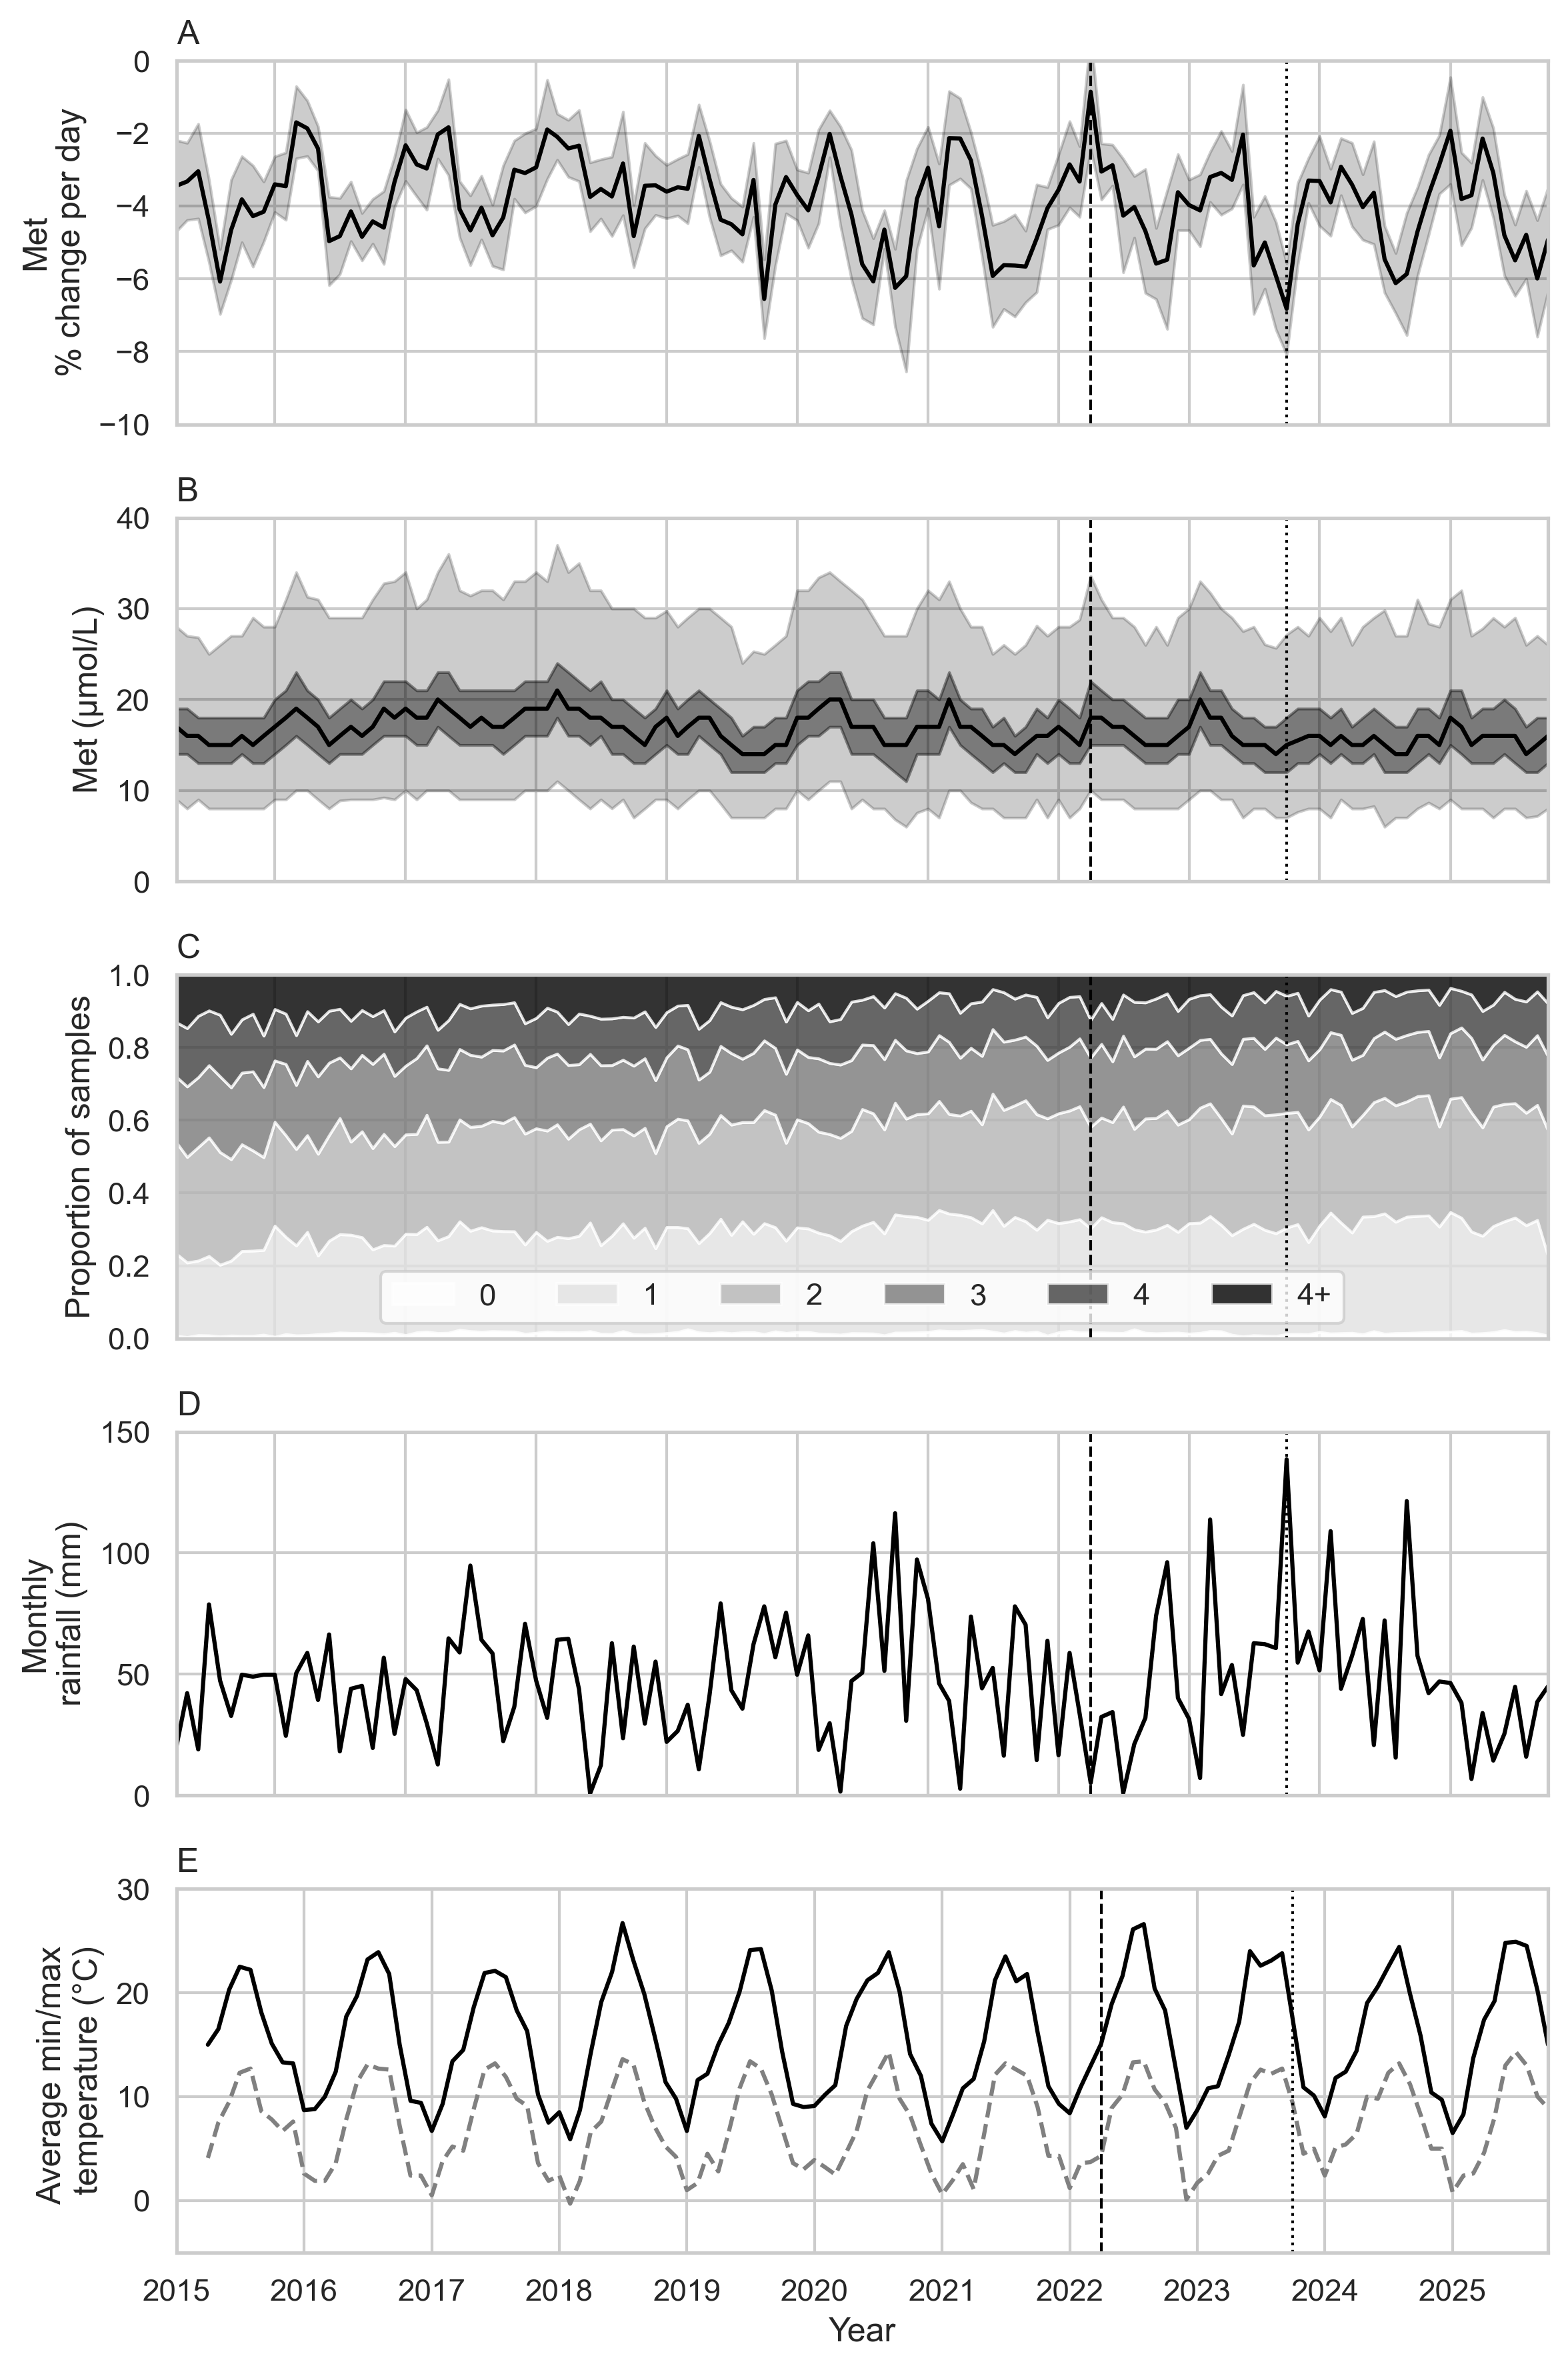

In [73]:
plot_year_month_stats(imd_noexc,'Met',ylim_stability=(-10,0),ylim_conc=(0,40))

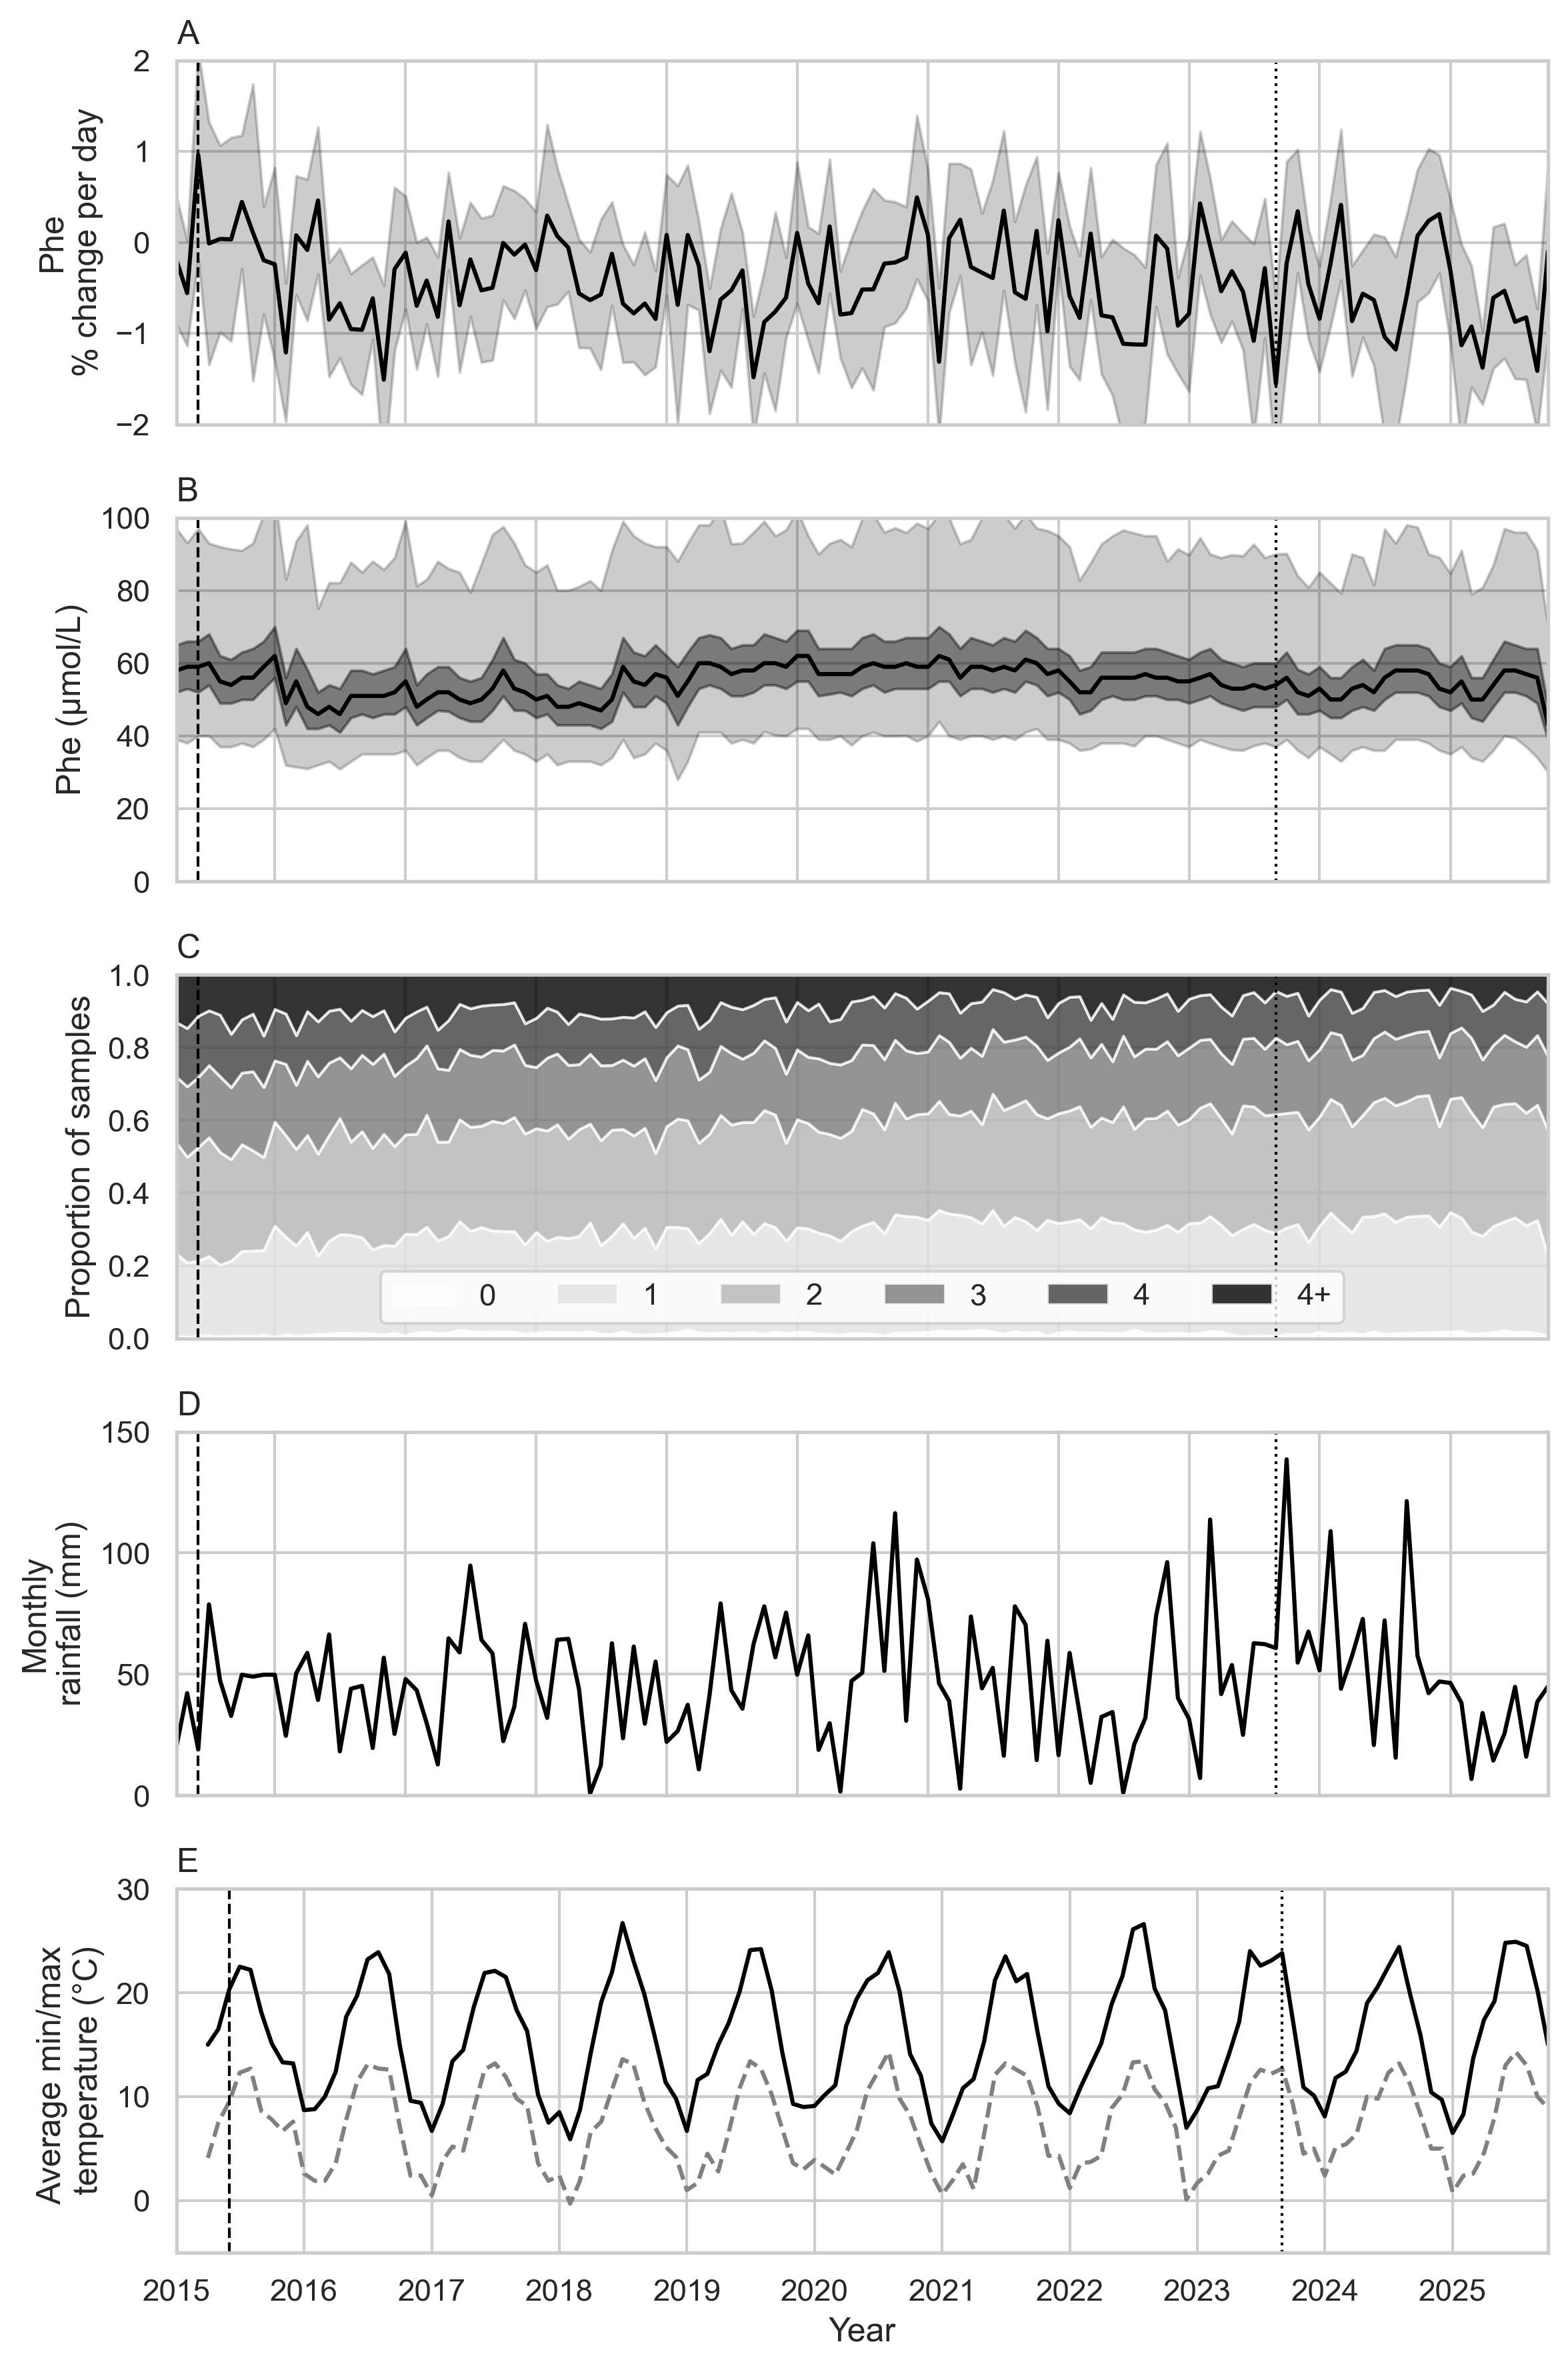

In [74]:
plot_year_month_stats(imd_noexc,'Phe',ylim_stability=(-2,2),ylim_conc=(0,100))

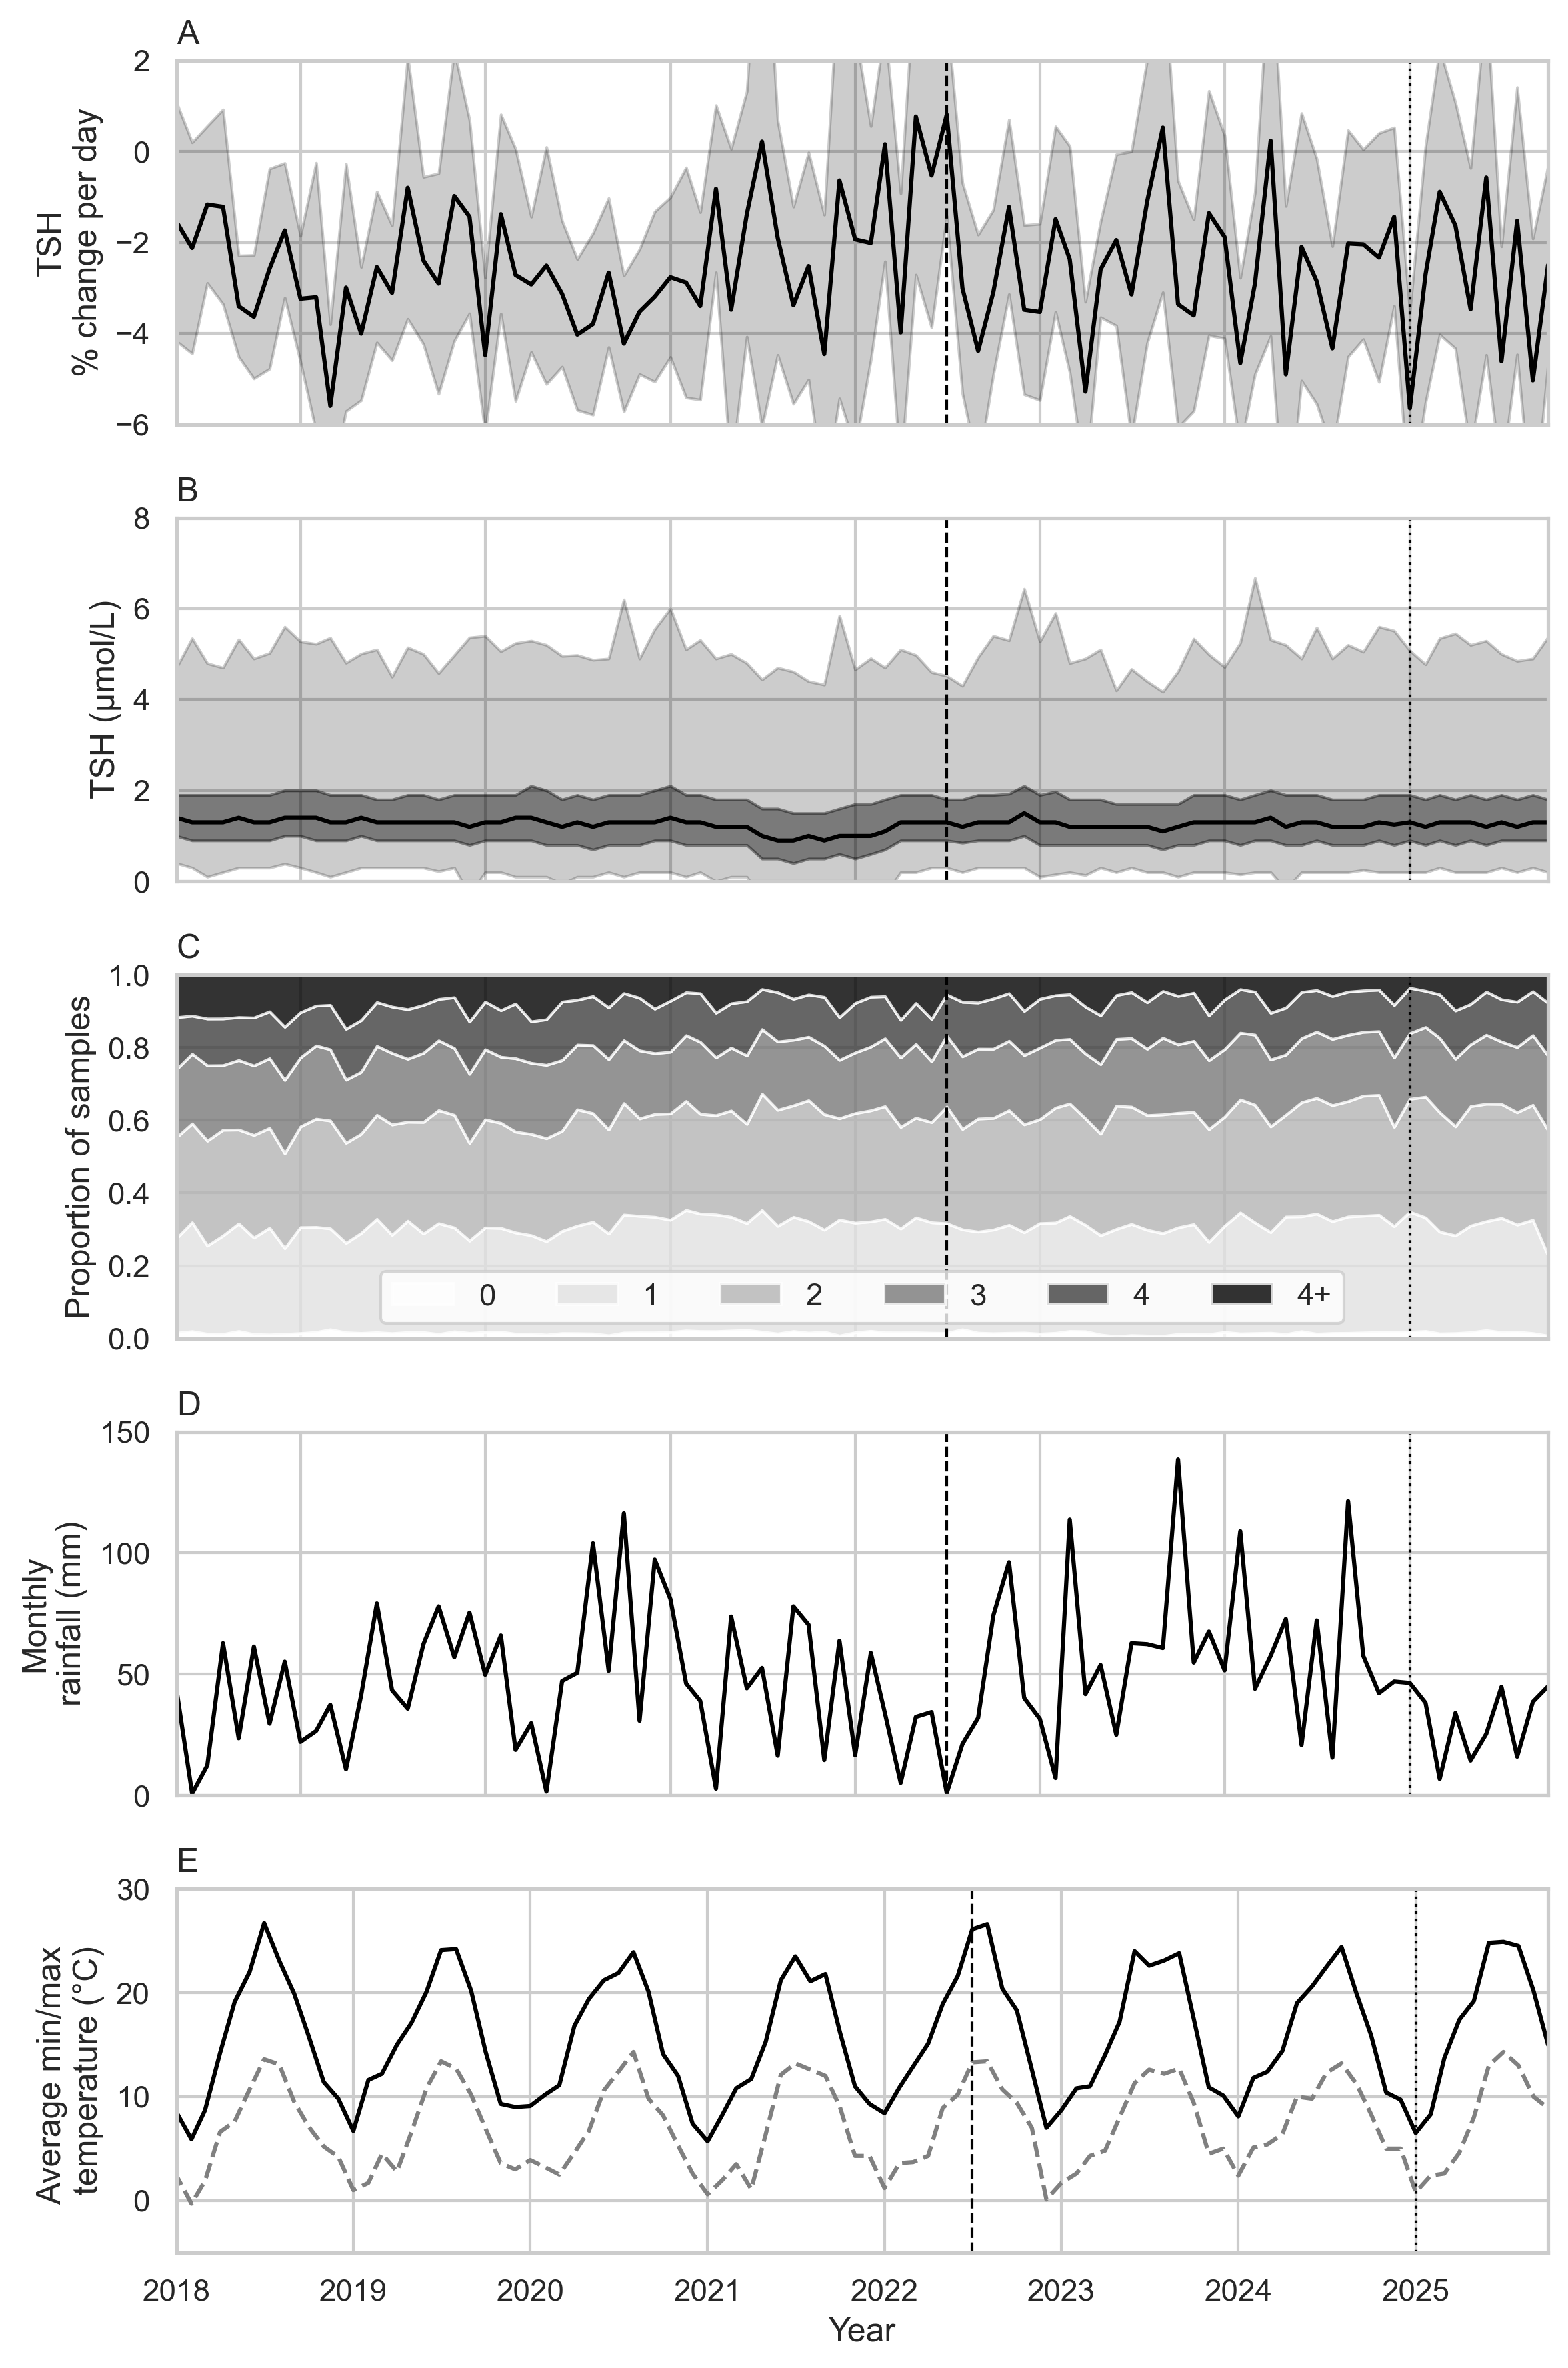

In [75]:
plot_year_month_stats(tsh_noexc,'TSH',ylim_stability=(-6,2),ylim_conc=(0,8))

## Comparison with historical weather extremes

In [76]:
met_summary = year_month_dataframe[
    (year_month_dataframe['Analyte'] == 'met') & 
    (year_month_dataframe['Predictor'] == 'Days to receive')
]

Largest drop in methionine concentration

In [77]:
met_summary[met_summary['Coefficient'] == met_summary['Coefficient'].min()]

,Analyte,Predictor,Coefficient,95% CI Lower,95% CI Upper,p-value,year_month,year,month
1644,met,Days to receive,-6.823691,-8.080194,-5.567187,1.860255e-26,2023-10,2023,10


Maximum rainfall

In [78]:
cambridge_niab[cambridge_niab['rain'] == cambridge_niab['rain'].max()]

,yyyy,mm,tmax,tmin,af,rain,year_month_dt
102,2023,10,17.5,9.4,0,138.6,2023-10-01


Smallest drop in methionine concentration

In [79]:
met_summary[met_summary['Coefficient'] == met_summary['Coefficient'].max()]

,Analyte,Predictor,Coefficient,95% CI Lower,95% CI Upper,p-value,year_month,year,month
1356,met,Days to receive,-0.854957,-2.417928,0.708014,0.283668,2022-04,2022,4


In [80]:
met_summary.sort_values(by='Coefficient')

,Analyte,Predictor,Coefficient,95% CI Lower,95% CI Upper,p-value,year_month,year,month
1644,met,Days to receive,-6.823691,-8.080194,-5.567187,1.860255e-26,2023-10,2023,10
876,met,Days to receive,-6.551121,-7.634140,-5.468102,2.010137e-32,2019-10,2019,10
1068,met,Days to receive,-6.246878,-7.317493,-5.176264,2.760174e-30,2020-10,2020,10
1804,met,Days to receive,-6.117383,-6.944364,-5.290402,1.241170e-47,2024-08,2024,8
76,met,Days to receive,-6.073479,-6.967684,-5.179273,1.967298e-40,2015-08,2015,8
...,...,...,...,...,...,...,...,...,...
556,met,Days to receive,-1.893224,-3.257416,-0.529032,6.527474e-03,2018-02,2018,2
204,met,Days to receive,-1.861954,-2.625000,-1.098909,1.730170e-06,2016-04,2016,4
412,met,Days to receive,-1.832203,-3.151819,-0.512587,6.502860e-03,2017-05,2017,5
188,met,Days to receive,-1.696289,-2.688782,-0.703796,8.086633e-04,2016-03,2016,3


In [81]:
cambridge_niab[cambridge_niab['year_month_dt'] == '2022-04-01']

,yyyy,mm,tmax,tmin,af,rain,year_month_dt
84,2022,4,15.1,4.3,4,5.2,2022-04-01


In [82]:
cambridge_niab.sort_values(by='rain')

,yyyy,mm,tmax,tmin,af,rain,year_month_dt
38,2018,6,22.0,10.7,0,0.8,2018-06-01
87,2022,7,26.1,13.3,0,1.0,2022-07-01
61,2020,5,19.4,6.7,2,1.6,2020-05-01
72,2021,4,11.7,1.1,13,2.8,2021-04-01
84,2022,4,15.1,4.3,4,5.2,2022-04-01
...,...,...,...,...,...,...,...
106,2024,2,11.8,5.1,3,109.0,2024-02-01
95,2023,3,11.0,4.3,4,113.8,2023-03-01
66,2020,10,14.1,8.2,0,116.4,2020-10-01
113,2024,9,19.9,11.2,0,121.4,2024-09-01
